# Занятие 6. Кинематика колёсных мобильных роботов — демонстрации

Конспект: лекция 6 (разделы 6.1–6.12 и приложения 6.А–6.Д). Модуль `wheeled.py`: дифференциальная схема, одометрия и её неопределённость, трицикл и автомобиль, омни- и меканум-платформы, манёвренность, неголономность, отслеживание траектории, мобильный манипулятор.

**Обозначения** (как в конспекте и в `00_Паспорт/Обозначения.md`): $\boldsymbol\xi=(x,y,\theta)^{\mathrm T}$ — поза корпуса (в коде массив `q`), $\dot{\boldsymbol\xi}_R=(v_x,v_y,\omega)^{\mathrm T}$ — скорость корпуса в связанных осях ($x$ вперёд, $y$ влево), $\dot{\boldsymbol\xi}=R_z(\theta)\dot{\boldsymbol\xi}_R$; $\dot{\boldsymbol\varphi}$ — скорости колёс, $r$ — радиус колеса; $b$ — колея (каждое колесо дифференциальной схемы удалено от $P$ на $l=b/2$); $\rho$ — радиус поворота со знаком ($\rho>0$ — МЦВ слева); $\Delta t$ — шаг; $d$, $\delta$ — база и угол руля; $l$ — радиус окружности колёс омни-платформы; $\dot{\boldsymbol\varphi}=H\dot{\boldsymbol\xi}_R$, $\dot{\boldsymbol\xi}_R=F\dot{\boldsymbol\varphi}$ ($F$ — матрица шасси, не сила).

**Порядок величин в чужом коде.** Скорости колёс в курсе идут в порядке $(\dot\varphi_r,\dot\varphi_l)$, а у `roboticstoolbox.DiffSteer` — $(v_L,v_R)$; блоки якобиана манипулятора в `kinlib` и Robotics Toolbox — $[\mathbf v;\boldsymbol\omega]$, в лекциях — $(\boldsymbol\omega;\mathbf v)$. Перед подключением чужой модели порядок и знаки проверяют на тестовом движении (демонстрации 1 и 12).

Демонстрации пронумерованы в порядке показа на занятии; каждая заканчивается числом или рисунком, которые совпадают с конспектом. Ячейки с ползунками (2 и 13) нужно запускать вживую; в сохранённом ноутбуке они показывают статичный кадр.

| № | Демонстрация | Конспект | Рисунок | Чем заканчивается |
|---|---|---|---|---|
| 1 | МЦВ и три случая движения дифференциальной схемы | § 6.4, пример 6.1 | рис. 6.3 | $v=0{,}5$ м/с, $\omega=0{,}667$ рад/с, $\rho=0{,}75$ м; сверка порядка входов с `rtb.DiffSteer` |
| 2 | Обратная задача о скорости и насыщение (пример 6.2) | § 6.4, пример 6.2 | рис. 6.4 | срезание: $\rho=0{,}45$ м, масштабирование: $\rho=0{,}40$ м; ползунки $(V_l,V_r)$ |
| 3 | Шаг одометрии: Эйлер, средняя точка, точная дуга (пример 6.3) | § 6.5, пример 6.3 | рис. 6.5 слева | $0{,}2498$ / $0{,}0052$ / $0$ м; наклоны 1 и 2; точная дуга = $\exp$ на $SE(2)$ |
| 4 | Систематические ошибки и UMBmark | § 6.5 | рис. 6.5 справа | $1{,}40$ м и $30{,}6^{\circ}$; $0{,}53$ м и повороты по $87{,}4^{\circ}$; поправки UMBmark |
| 5 | Реалистичная одометрия: неопределённость | § 6.5, прил. 6.Б | рис. 6.6 | $\sigma_x\approx0{,}014$, $\sigma_y\approx0{,}22$ м, $\sigma_\theta\approx5{,}4^{\circ}$ на 4 м; «банан» |
| 6 | Трицикл и автомобиль | § 6.6, пример 6.4, прил. 6.Д | рис. 6.7 | $27{,}4^{\circ}$ / $21{,}7^{\circ}$ / $24{,}2^{\circ}$, $1:1{,}31$; одинаковые углы — $\operatorname{rank}C_1=3$ |
| 7 | Трёхколёсная омни-платформа | § 6.7, пример 6.5 | рис. 6.8 | $\det H=4156{,}9$, $(4{,}00;\,-2{,}46;\,4{,}46)$; тяга по радиусам — $\det H=0$ |
| 8 | Меканум-платформа | § 6.8, примеры 6.6, 6.7 | рис. 6.9–6.11 | $(-1{,}85;\,13{,}85;\,6{,}15;\,5{,}85)$; невязка $0{,}15\cdot(1,1,-1,-1)$; переставленные колёса — $(40;\,40;\,3{,}4)$ |
| 9 | Ранг $C_1$ и манёвренность | § 6.9, прил. 6.Д | рис. 6.12 | $(\delta_m,\delta_s)$ пяти типов; три фиксированных колеса — rank 3; бортовой поворот — rank 2 |
| 10 | Скобка Ли и параллельная парковка | § 6.10 | рис. 6.13 | $(0{,}105;\,-0{,}339)$; $0{,}482$ м и $2{,}736$ м за цикл; пятно $6{,}94$ м |
| 11 | Отслеживание траектории вынесенной точкой | § 6.10 | рис. 6.14 | влияние $l_B$ на точность оси и на $\omega$; pure pursuit |
| 12 | Мобильный манипулятор (пример 6.8) | § 6.11, пример 6.8 | рис. 6.15 | три набора весов, $J\mathbf z=(0{,}1;\,0)$; UR5e на меканум-платформе |
| 13 | Интерактивная модель меканум-платформы | § 6.8 | — | ползунки $(v_x,v_y,\omega)$: скорости колёс, МЦВ, траектория |

In [1]:
import sys, os, warnings
sys.path.insert(0, os.path.abspath('.'))
import numpy as np
import matplotlib.pyplot as plt
from wheeled import *
np.set_printoptions(precision=4, suppress=True)
warnings.filterwarnings('ignore')
%matplotlib inline
deg, rad = np.degrees, np.radians
wrap = lambda a: (a + np.pi) % (2*np.pi) - np.pi
try:
    import roboticstoolbox as rtb               # только для сверок (демонстрации 1, 6, 12)
except ImportError:
    rtb = None; print('roboticstoolbox не установлен: сверки с ним будут пропущены (pip install roboticstoolbox-python)')
try:
    from ipywidgets import interact, FloatSlider
except ImportError:
    interact = None; print('ipywidgets не установлен: интерактивные ячейки покажут только статичную картинку')

## 1. МЦВ и три случая движения дифференциальной схемы (§ 6.4, пример 6.1)

$v=\dfrac{V_r+V_l}{2}$, $\omega=\dfrac{V_r-V_l}{b}$, $\rho=\dfrac{b}{2}\cdot\dfrac{V_r+V_l}{V_r-V_l}$; МЦВ лежит на колёсной оси: $x_c=x-\rho\sin\theta$, $y_c=y+\rho\cos\theta$.
Ожидаем для $r=0{,}05$ м, $b=0{,}30$ м, $\dot\varphi_r=12$, $\dot\varphi_l=8$ рад/с: $v=0{,}5$ м/с, $\omega=0{,}667$ рад/с, $\rho=0{,}75$ м.
Три «режима» — прямая, разворот на месте, вращение вокруг колеса — это одна точка МЦВ, которая скользит по колёсной оси при изменении $V_l$.
В конце сверим порядок входов с моделью `DiffSteer` из Robotics Toolbox.

пример 6.1: V_r = 0.60 м/с, V_l = 0.40 м/с -> v = 0.500 м/с, ω = 0.667 рад/с, ρ = 0.750 м;  проверка ωρ = 0.500 м/с
МЦВ в начальный момент: (x_c, y_c) = (0.00; 0.75) м — слева от робота
G(0) = R_z(0) F =
 [[ 0.025   0.025 ]
 [ 0.      0.    ]
 [ 0.1667 -0.1667]] 
ранг G = 2 при любом θ (проверено при θ = 0,7)
МЦВ скользит по оси: при V_r = 0,6 м/с и V_l = 0.5 -> ρ = 1.650 м, 0.4 -> ρ = 0.750 м, 0.0 -> ρ = 0.150 м, -0.6 -> ρ = 0.000 м


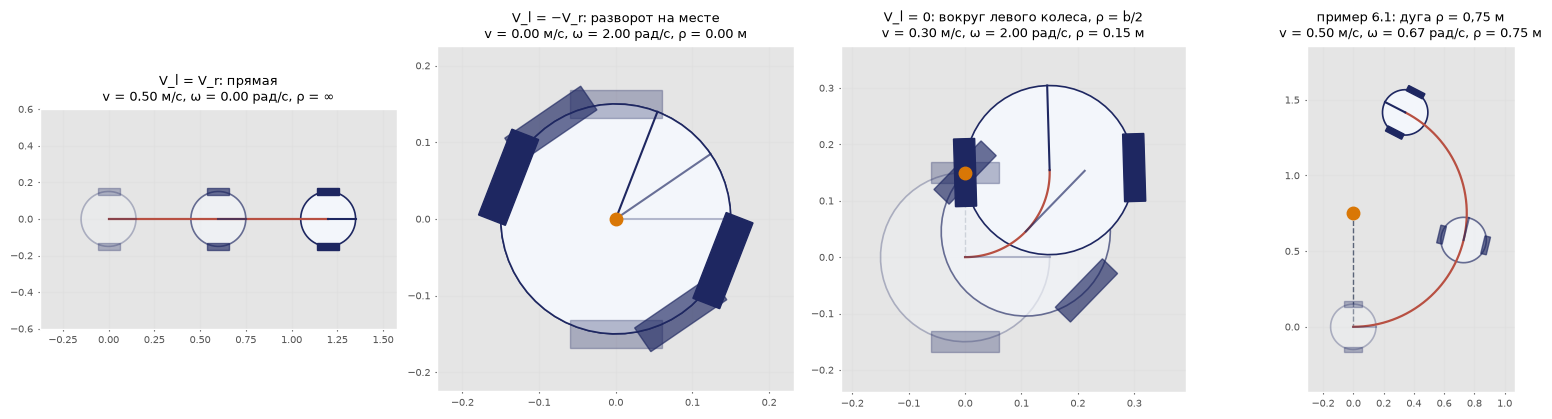

rtb.DiffSteer(W = 0,30).deriv(ξ = 0, u = (0,6; 0,4)) = [ 0.5     0.     -0.6667]  ->  ω = -0.667 рад/с
курс, dd_fk(φ̇_r, φ̇_l) при V_r = 0,6, V_l = 0,4:          ω = +0.667 рад/с
у DiffSteer вход u = (v_L, v_R); после перестановки u = (0,4; 0,6): ω = +0.667 рад/с — совпадает с курсом
мораль: перед подключением чужой модели или контроллера проверьте порядок и знаки входов на тестовом движении


In [2]:
r, b = DD_R, DD_B
v, w = dd_fk(12.0, 8.0); rho, icc = dd_icc(np.zeros(3), v, w)
print('пример 6.1: V_r = %.2f м/с, V_l = %.2f м/с -> v = %.3f м/с, ω = %.3f рад/с, ρ = %.3f м;  проверка ωρ = %.3f м/с' % (r*12, r*8, v, w, rho, w*rho))
print('МЦВ в начальный момент: (x_c, y_c) = (%.2f; %.2f) м — слева от робота' % tuple(icc))
print('G(0) = R_z(0) F =\n', dd_G(0.0), '\nранг G = %d при любом θ (проверено при θ = 0,7)' % np.linalg.matrix_rank(dd_G(0.7)))
print('МЦВ скользит по оси: при V_r = 0,6 м/с и V_l =', ', '.join('%.1f -> ρ = %.3f м' % (Vl, dd_icc(np.zeros(3), *dd_fk(0.6/r, Vl/r))[0]) for Vl in (0.5, 0.4, 0.0, -0.6)))

cases = [('V_l = V_r: прямая', 10.0, 10.0, 2.4), ('V_l = −V_r: разворот на месте', 6.0, -6.0, 0.6),
         ('V_l = 0: вокруг левого колеса, ρ = b/2', 12.0, 0.0, 0.8), ('пример 6.1: дуга ρ = 0,75 м', 12.0, 8.0, 4.0)]
fig, axs = plt.subplots(1, 4, figsize=(16, 4.2))
for ax, (ttl, pr, pl, T) in zip(axs, cases):
    v_, w_ = dd_fk(pr, pl)
    Pth = integrate(np.zeros(3), v_, w_, T/60, 60); draw_path(ax, Pth)
    for k in (0, 30, 60): draw_diffdrive(ax, Pth[k], alpha=0.3 + 0.7*k/60)
    rho_, icc_ = dd_icc(Pth[0], v_, w_)
    if icc_ is not None:
        ax.plot(icc_[0], icc_[1], 'o', color=AMB, ms=9, zorder=8); ax.plot([icc_[0], Pth[0, 0]], [icc_[1], Pth[0, 1]], color=GREY, lw=1, ls='--')
    ax.set_aspect('equal'); ax.grid(alpha=.3); ax.margins(0.15)
    if icc_ is None: ax.set_ylim(-0.6, 0.6)
    ax.set_title('%s\nv = %.2f м/с, ω = %.2f рад/с, ρ = %s' % (ttl, v_, w_, '∞' if icc_ is None else '%.2f м' % rho_), fontsize=9.5)
plt.tight_layout(); plt.show()

# сверка с Robotics Toolbox: порядок входов
if rtb is not None:
    veh = rtb.DiffSteer(W=b)
    xd = veh.deriv(np.zeros(3), [0.6, 0.4])
    print('rtb.DiffSteer(W = 0,30).deriv(ξ = 0, u = (0,6; 0,4)) = %s  ->  ω = %+.3f рад/с' % (xd.round(4), xd[2]))
    print('курс, dd_fk(φ̇_r, φ̇_l) при V_r = 0,6, V_l = 0,4:          ω = %+.3f рад/с' % w)
    xd2 = veh.deriv(np.zeros(3), [0.4, 0.6])
    print('у DiffSteer вход u = (v_L, v_R); после перестановки u = (0,4; 0,6): ω = %+.3f рад/с — совпадает с курсом' % xd2[2])
    print('мораль: перед подключением чужой модели или контроллера проверьте порядок и знаки входов на тестовом движении')

## 2. Обратная задача о скорости и насыщение (пример 6.2) (§ 6.4, пример 6.2)

$\dot\varphi_{r,l}=\dfrac1r\Big(v\pm\dfrac b2\omega\Big)$; ограничение $\lvert\dot\varphi\rvert\le\dot\varphi_{\max}$ даёт ромб $\lvert v\rvert+\dfrac b2\lvert\omega\rvert\le r\dot\varphi_{\max}$ с вершинами $(\pm r\dot\varphi_{\max},0)$ и $(0,\pm2r\dot\varphi_{\max}/b)$.
Команда $v=0{,}8$ м/с, $\omega=2{,}0$ рад/с ($\rho=0{,}4$ м) при $\dot\varphi_{\max}=20$ рад/с. Ожидаем: $22$ и $10$ рад/с; срезание → $0{,}75$ м/с, $1{,}67$ рад/с, $\rho=0{,}45$ м; масштабирование с коэффициентом $20/22$ → $0{,}727$ м/с, $1{,}82$ рад/с, $\rho=0{,}40$ м.
Во второй ячейке — ползунки $(V_l,V_r)$: команда отмечена на ромбе, а если она вне ромба — рядом её масштабированная копия.

обратная задача: v = 0.8 м/с, ω = 2.0 рад/с -> φ̇_r = 22.0, φ̇_l = 10.0 рад/с; ρ = 0.40 м
вершины ромба: v_max = 1.00 м/с, ω_max = 6.67 рад/с
срезание        : φ̇ = (20.00; 10.00) рад/с -> v = 0.750 м/с, ω = 1.667 рад/с, ρ = 0.450 м
масштабирование : φ̇ = (20.00; 9.09) рад/с -> v = 0.727 м/с, ω = 1.818 рад/с, ρ = 0.400 м
коэффициент масштабирования 20/22 = 0.909


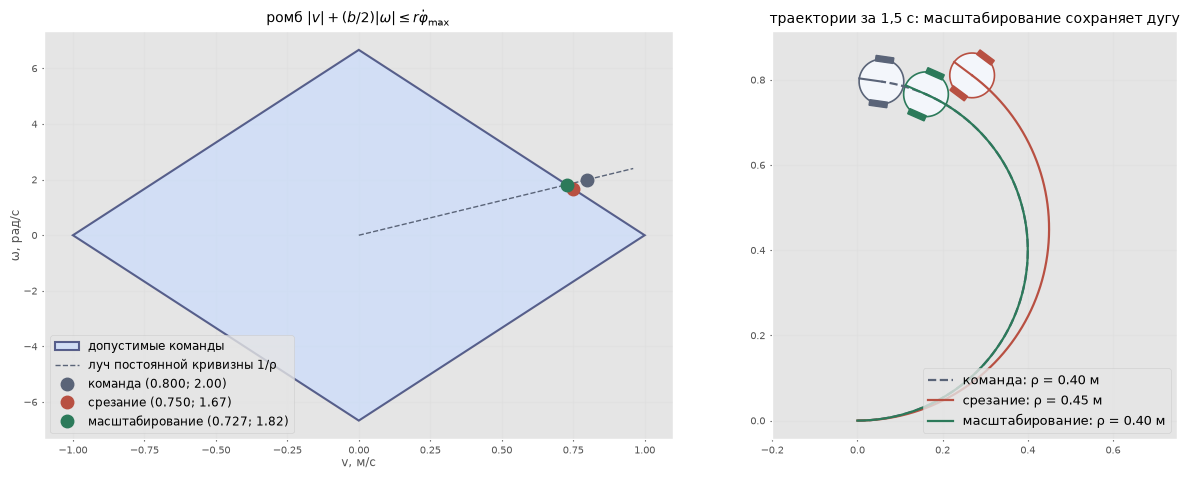

In [3]:
v0, w0, pmax = 0.8, 2.0, 20.0; pr, pl = dd_ik(v0, w0)
print('обратная задача: v = %.1f м/с, ω = %.1f рад/с -> φ̇_r = %.1f, φ̇_l = %.1f рад/с; ρ = %.2f м' % (v0, w0, pr, pl, v0/w0))
vm, wm = dd_diamond(pmax); print('вершины ромба: v_max = %.2f м/с, ω_max = %.2f рад/с' % (vm, wm))
res = {'команда': (v0, w0)}
for mode, nm in (('clip', 'срезание'), ('scale', 'масштабирование')):
    s = dd_saturate(pr, pl, pmax, mode); vv, ww = dd_fk(s[0], s[1]); res[nm] = (vv, ww)
    print('%-16s: φ̇ = (%.2f; %.2f) рад/с -> v = %.3f м/с, ω = %.3f рад/с, ρ = %.3f м' % (nm, s[0], s[1], vv, ww, vv/ww))
print('коэффициент масштабирования 20/22 = %.3f' % (pmax/pr))
fig, axs = plt.subplots(1, 2, figsize=(13, 4.8)); cols = {'команда': GREY, 'срезание': RED, 'масштабирование': GREEN}
ax = axs[0]
ax.fill([vm, 0, -vm, 0], [0, wm, 0, -wm], facecolor=ICE, edgecolor=NAVY, lw=1.5, alpha=0.7, label='допустимые команды')
ax.plot([0, 1.2*v0], [0, 1.2*w0], color=GREY, lw=1, ls='--', label='луч постоянной кривизны 1/ρ')
for nm, (vv, ww) in res.items(): ax.plot(vv, ww, 'o', color=cols[nm], ms=9, label='%s (%.3f; %.2f)' % (nm, vv, ww), zorder=5)
ax.set_xlabel('v, м/с'); ax.set_ylabel('ω, рад/с'); ax.grid(alpha=.3); ax.legend(fontsize=8.5, loc='lower left')
ax.set_title(r'ромб $|v| + (b/2)|\omega| \leq r\dot\varphi_{\max}$', fontsize=10)
ax = axs[1]
for nm, (vv, ww) in res.items():
    Pth = integrate(np.zeros(3), vv, ww, 0.02, 75); draw_path(ax, Pth, color=cols[nm], label='%s: ρ = %.2f м' % (nm, vv/ww), ls='--' if nm == 'команда' else '-'); draw_diffdrive(ax, Pth[-1], color=cols[nm], scale=0.35)
ax.set_aspect('equal'); ax.grid(alpha=.3); ax.set_xlim(-0.2, 0.75); ax.legend(fontsize=9, loc='lower right'); ax.set_title('траектории за 1,5 с: масштабирование сохраняет дугу', fontsize=10)
plt.tight_layout(); plt.show()

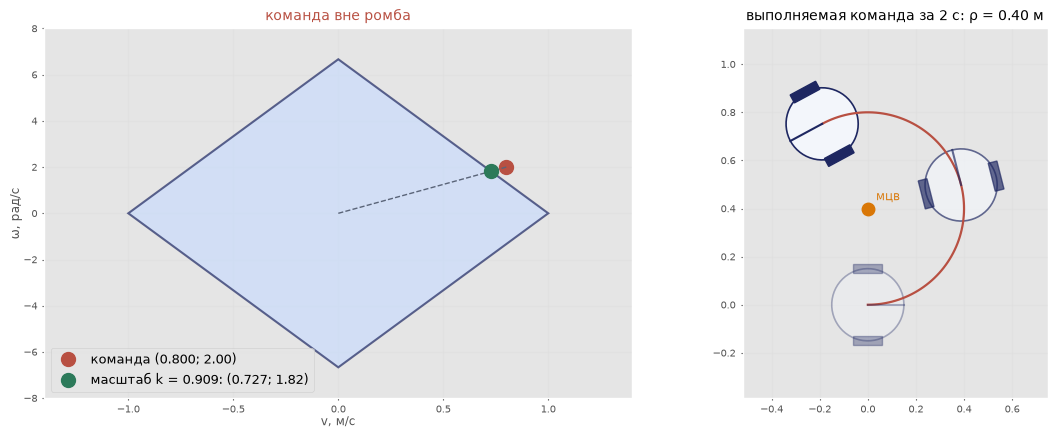

interactive(children=(FloatSlider(value=0.5, description='V_l', max=1.4, min=-1.4, step=0.05), FloatSlider(val…

In [4]:
def show_dd(V_l=0.5, V_r=1.1, pmax=20.0):
    """Ползунки (V_l, V_r), м/с: команда на ромбе, при выходе за ромб — масштабированная команда и её дуга за 2 с."""
    v_, w_ = dd_fk(V_r/DD_R, V_l/DD_R); k = min(1.0, pmax*DD_R/max(abs(V_l), abs(V_r), 1e-12))
    vs, ws = k*v_, k*w_; vm, wm = dd_diamond(pmax)
    fig, axs = plt.subplots(1, 2, figsize=(12, 4.4))
    ax = axs[0]; ax.fill([vm, 0, -vm, 0], [0, wm, 0, -wm], facecolor=ICE, edgecolor=NAVY, lw=1.5, alpha=0.7)
    ax.plot(v_, w_, 'o', color=RED if k < 1 else NAVY, ms=10, label='команда (%.3f; %.2f)' % (v_, w_))
    if k < 1:
        ax.plot([0, v_], [0, w_], color=GREY, ls='--', lw=1); ax.plot(vs, ws, 'o', color=GREEN, ms=10, label='масштаб k = %.3f: (%.3f; %.2f)' % (k, vs, ws))
    ax.set_xlim(-1.4, 1.4); ax.set_ylim(-8, 8); ax.grid(alpha=.3); ax.legend(fontsize=9, loc='lower left'); ax.set_xlabel('v, м/с'); ax.set_ylabel('ω, рад/с')
    ax.set_title('команда %s ромба' % ('вне' if k < 1 else 'внутри'), color=RED if k < 1 else NAVY, fontsize=10)
    ax = axs[1]; Pth = integrate(np.zeros(3), vs, ws, 0.02, 100); draw_path(ax, Pth)
    for j in (0, 50, 100): draw_diffdrive(ax, Pth[j], alpha=0.35 + 0.65*j/100)
    rho_, icc_ = dd_icc(np.zeros(3), vs, ws)
    if icc_ is not None and abs(rho_) < 5:
        ax.plot(icc_[0], icc_[1], 'o', color=AMB, ms=9); ax.annotate('МЦВ', icc_, textcoords='offset points', xytext=(6, 6), color=AMB)
    ax.set_aspect('equal'); ax.grid(alpha=.3); ax.margins(0.2)
    ax.set_title('выполняемая команда за 2 с: ρ = %s' % ('∞' if icc_ is None else '%.2f м' % rho_), fontsize=10)
    plt.tight_layout(); plt.show()

show_dd(0.5, 1.1)     # статичный кадр: команда примера 6.2 (V_l = 0,5, V_r = 1,1 м/с) и её масштабирование
if interact is not None:
    interact(show_dd, V_l=FloatSlider(min=-1.4, max=1.4, step=0.05, value=0.5), V_r=FloatSlider(min=-1.4, max=1.4, step=0.05, value=1.1), pmax=FloatSlider(min=5, max=30, step=1, value=20))

## 3. Шаг одометрии: Эйлер, средняя точка, точная дуга (пример 6.3) (§ 6.5, пример 6.3)

Три формулы шага: метод Эйлера (курс начала шага), средняя точка (курс $\theta+\Delta\theta/2$), точная дуга (поворот вокруг МЦВ).
$v=0{,}5$ м/с, $\omega=0{,}5$ рад/с ($\rho=1$ м), $\Delta t=0{,}5$ с, $\Delta\theta=0{,}25$ рад, 13 шагов (около половины окружности, $3{,}25$ рад). Ожидаем ошибки положения $0{,}2498$, $0{,}0052$ и $0$ м.
Ломаная Эйлера — правильный многоугольник со стороной $v\Delta t=0{,}25$ м, вписанный в окружность радиуса $0{,}25/(2\sin0{,}125)=1{,}0026$ м с центром $(0{,}125;\ 0{,}995)$, сдвинутым вперёд на $v\Delta t/2$. Поэтому ошибка Эйлера колеблется: $0{,}031$ м после первого шага, около $0{,}25$ м на полуокружности, $0{,}004$ м после полного оборота (25 шагов). Порядок метода показывает график ошибки от шага в логарифмическом масштабе: наклоны 1 и 2.
Наконец, точный шаг совпадает с экспонентой на $SE(2)$, $T'=T\exp(\Delta t\,X)$, в том числе при $v_y\ne0$.

метод Эйлера  : ошибка положения после 13 шагов = 0.2498 м
средняя точка : ошибка положения после 13 шагов = 0.0052 м
точная дуга   : ошибка положения после 13 шагов = 0.0000 м
оценка для средней точки: относительная ошибка Δθ²/24 = 0.0026 от перемещения 2.00 м -> 0.0052 м
вершины ломаной Эйлера лежат на окружности: центр (0.125; 0.995), радиус 1.0026 м = 0,25/(2 sin 0,125) = 1.0026 м
ошибка Эйлера по шагам: 1 -> 0.0312, 6 -> 0.1706, 12 -> 0.2496, 13 -> 0.2498, 18 -> 0.1947, 24 -> 0.0353, 25 -> 0.0042 м
наклон графика ошибки (метод Эйлера): 1.00
наклон графика ошибки (средняя точка): 2.00


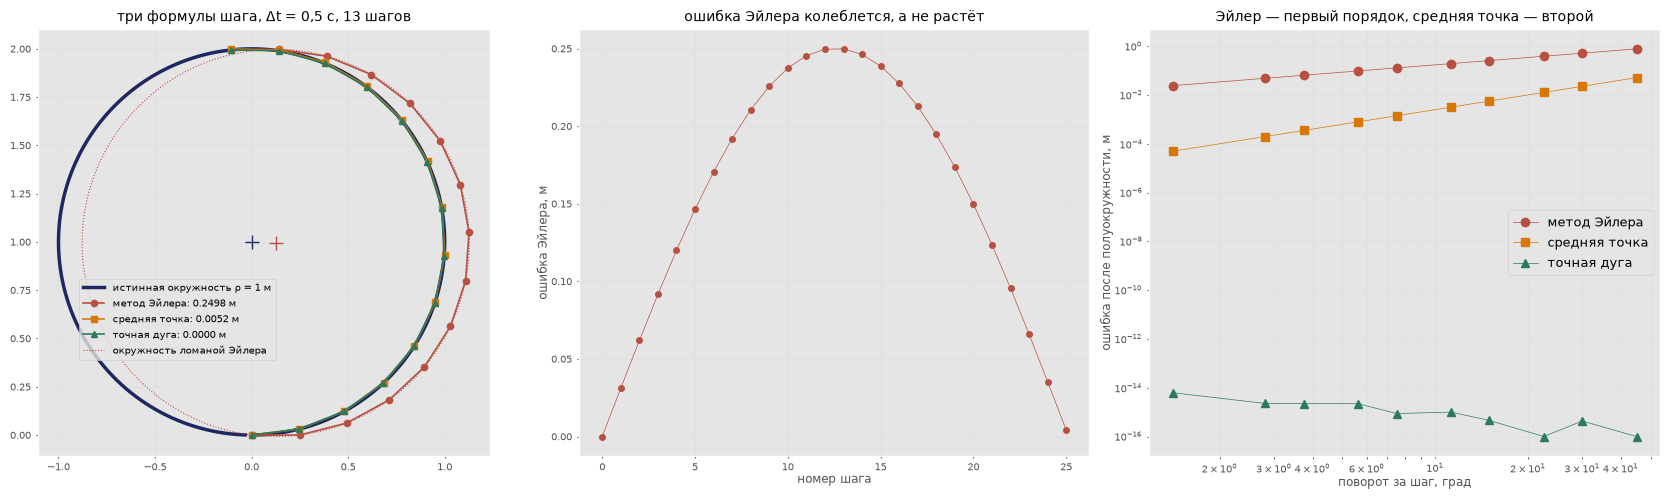

ξ̇_R = (0.5; 0.0; 0.5): |se2_exp − T·expm(ΔtX)| = 8.3e-17;  |se2_exp − step_exact| = 5.6e-17
ξ̇_R = (0.3; 0.2; 0.5): |se2_exp − T·expm(ΔtX)| = 2.8e-17
ξ̇_R = (0.3; -0.4; -1.2): |se2_exp − T·expm(ΔtX)| = 6.9e-17
ξ̇_R = (0.4; 0.1; 0.0): |se2_exp − T·expm(ΔtX)| = 5.6e-17


In [5]:
from scipy.linalg import expm
v, w, dt, n = 0.5, 0.5, 0.5, 13
q_true = lambda k: step_exact(np.zeros(3), v, w, k*dt)
names = {'euler': ('метод Эйлера', RED, 'o'), 'mid': ('средняя точка', AMB, 's'), 'exact': ('точная дуга', GREEN, '^')}
fig, axs = plt.subplots(1, 3, figsize=(17, 5))
ax = axs[0]; t = np.linspace(0, 25*dt, 400); ax.plot(v/w*np.sin(w*t), v/w*(1 - np.cos(w*t)), color=NAVY, lw=2.5, label='истинная окружность ρ = 1 м')
for m, (nm, col, mk) in names.items():
    Pm = integrate(np.zeros(3), v, w, dt, n, m); err = np.hypot(*(Pm[-1, :2] - q_true(n)[:2]))
    print('%-14s: ошибка положения после %d шагов = %.4f м' % (nm, n, err))
    ax.plot(Pm[:, 0], Pm[:, 1], '-' + mk, color=col, lw=1.2, ms=4.5, label='%s: %.4f м' % (nm, err))
disp = np.hypot(*q_true(n)[:2])
print('оценка для средней точки: относительная ошибка Δθ²/24 = %.4f от перемещения %.2f м -> %.4f м' % ((w*dt)**2/24, disp, (w*dt)**2/24*disp))
E = integrate(np.zeros(3), v, w, dt, 25, 'euler')                    # полный оборот: 25 шагов
A_ = np.column_stack([2*E[:, 0], 2*E[:, 1], np.ones(26)]); c_ = np.linalg.lstsq(A_, (E[:, :2]**2).sum(1), rcond=None)[0]
Rc = np.sqrt(c_[2] + c_[0]**2 + c_[1]**2)
print('вершины ломаной Эйлера лежат на окружности: центр (%.3f; %.3f), радиус %.4f м = 0,25/(2 sin 0,125) = %.4f м' % (c_[0], c_[1], Rc, v*dt/(2*np.sin(w*dt/2))))
tt = np.linspace(0, 2*np.pi, 200); ax.plot(c_[0] + Rc*np.cos(tt), c_[1] + Rc*np.sin(tt), color=RED, lw=0.8, ls=':', label='окружность ломаной Эйлера')
ax.plot(*c_[:2], '+', color=RED, ms=10); ax.plot(0, 1, '+', color=NAVY, ms=10)
ax.set_aspect('equal'); ax.grid(alpha=.3); ax.legend(fontsize=7.5, loc='center left', bbox_to_anchor=(0.08, 0.32)); ax.set_title('три формулы шага, Δt = 0,5 с, 13 шагов', fontsize=10)

ax = axs[1]; ks = np.arange(26); eE = np.array([np.hypot(*(E[k, :2] - q_true(k)[:2])) for k in ks])
ax.plot(ks, eE, 'o-', color=RED, ms=4); ax.set_xlabel('номер шага'); ax.set_ylabel('ошибка Эйлера, м'); ax.grid(alpha=.3)
ax.set_title('ошибка Эйлера колеблется, а не растёт', fontsize=10)
print('ошибка Эйлера по шагам:', ', '.join('%d -> %.4f' % (k, eE[k]) for k in (1, 6, 12, 13, 18, 24, 25)), 'м')

ax = axs[2]; T = np.pi/w; q_half = step_exact(np.zeros(3), v, w, T); ns = np.array([4, 6, 8, 12, 16, 24, 32, 48, 64, 128])
for m in ('euler', 'mid', 'exact'):
    errs = np.array([np.hypot(*(integrate(np.zeros(3), v, w, T/k, k, m)[-1, :2] - q_half[:2])) for k in ns])
    ax.loglog(deg(w*T/ns), np.maximum(errs, 1e-16), '-' + names[m][2], color=names[m][1], label=names[m][0])
    if m != 'exact':
        sel = ns >= 8; print('наклон графика ошибки (%s): %.2f' % (names[m][0], np.polyfit(np.log(T/ns[sel]), np.log(errs[sel]), 1)[0]))
ax.set_xlabel('поворот за шаг, град'); ax.set_ylabel('ошибка после полуокружности, м'); ax.grid(alpha=.3, which='both'); ax.legend(fontsize=9)
ax.set_title('Эйлер — первый порядок, средняя точка — второй', fontsize=10)
plt.tight_layout(); plt.show()

q0 = np.array([0.3, -0.2, 0.7])
for (vx, vy, w_) in ((0.5, 0.0, 0.5), (0.3, 0.2, 0.5), (0.3, -0.4, -1.2), (0.4, 0.1, 0.0)):
    a = se2_exp(q0, vx, vy, w_, dt); bM = se2_from_matrix(se2_matrix(q0).dot(expm(dt*se2_twist(vx, vy, w_))))
    extra = ';  |se2_exp − step_exact| = %.1e' % np.abs(a - step_exact(q0, vx, w_, dt)).max() if vy == 0 else ''
    print('ξ̇_R = (%.1f; %.1f; %.1f): |se2_exp − T·expm(ΔtX)| = %.1e%s' % (vx, vy, w_, np.abs(a - bM).max(), extra))

## 4. Систематические ошибки и UMBmark (§ 6.5)

Робот отрабатывает квадрат $4\times4$ м по номинальной модели ($r=0{,}05$, $b=0{,}30$ м): прямые с равными путями колёс и развороты на месте на $90^{\circ}$. Одометрия по той же модели считает, что он вернулся в начало. На самом деле (а) правое колесо больше левого на один процент ($r_R/r_L=1{,}005/0{,}995$), (б) колея больше расчётной на три процента.
Ожидаем: (а) против часовой стрелки — удаление $1{,}40$ м и ошибка курса $30{,}6^{\circ}$, по часовой — $1{,}60$ м; на первой прямой поворот на $0{,}13$ рад и уход вбок около $0{,}27$ м; (б) удаление $0{,}53$ м в обе стороны, зеркальные точки, каждый поворот $90/1{,}03=87{,}4^{\circ}$.
Затем метод UMBmark (Боренштейн и Фэн): по абсциссам конечных точек двух обходов $\alpha=\dfrac{x_{cw}+x_{ccw}}{-4L}$ (недоворот на повороте, ошибка колеи), $\beta=\dfrac{x_{cw}-x_{ccw}}{-4L}$ (поворот на прямой, разные диаметры), $\rho_\beta=\dfrac{L/2}{\sin(\beta/2)}$, $E_d=\dfrac{D_R}{D_L}=\dfrac{\rho_\beta+b/2}{\rho_\beta-b/2}$, $E_b=\dfrac{\pi/2}{\pi/2-\alpha}$. Поправки вводят в модель контроллера как множители радиусов и колеи и повторяют обход. Формулы линейны по ошибкам, поэтому при ошибках такого размера тест повторяют 2–3 раза.

диаметры: правое колесо больше на 1 %  против часовой  конец = (+1.216; -0.694) м, удаление 1.40 м, ошибка курса +30.6°
диаметры: правое колесо больше на 1 %  по часовой      конец = (-0.793; -1.389) м, удаление 1.60 м, ошибка курса +30.6°
колея больше расчётной на 3 %          против часовой  конец = (-0.348; +0.399) м, удаление 0.53 м, ошибка курса -10.5°
колея больше расчётной на 3 %          по часовой      конец = (-0.348; -0.399) м, удаление 0.53 м, ошибка курса +10.5°
первая прямая 4 м при разнице диаметров: поворот 0.133 рад = 7.6°, уход вбок 0.27 м (оценка κs²/2 = 0.27 м)
ошибка колеи: каждый поворот на 90° выполняется на 87.4°, то есть короче на 2.6°

UMBmark при обеих ошибках (истина: r_R/r_L = 1.0101, b = 0.3090 м):


  обход 0: модель r_R/r_L = 1.0000, b = 0.3000 м;  удаление: против часовой 0.905 м, по часовой 2.135 м;  α = +0.69°, β = +6.06° -> E_d = 1.00796, E_b = 1.0078
  обход 1: модель r_R/r_L = 1.0080, b = 0.3023 м;  удаление: против часовой 0.081 м, по часовой 0.706 м;  α = +1.80°, β = +1.39° -> E_d = 1.00182, E_b = 1.0204


  обход 2: модель r_R/r_L = 1.0098, b = 0.3085 м;  удаление: против часовой 0.008 м, по часовой 0.066 м;  α = +0.15°, β = +0.19° -> E_d = 1.00024, E_b = 1.0016
  обход 3: модель r_R/r_L = 1.0100, b = 0.3090 м;  удаление: против часовой 0.001 м, по часовой 0.002 м;  α = +0.00°, β = +0.01° -> E_d = 1.00001, E_b = 1.0000


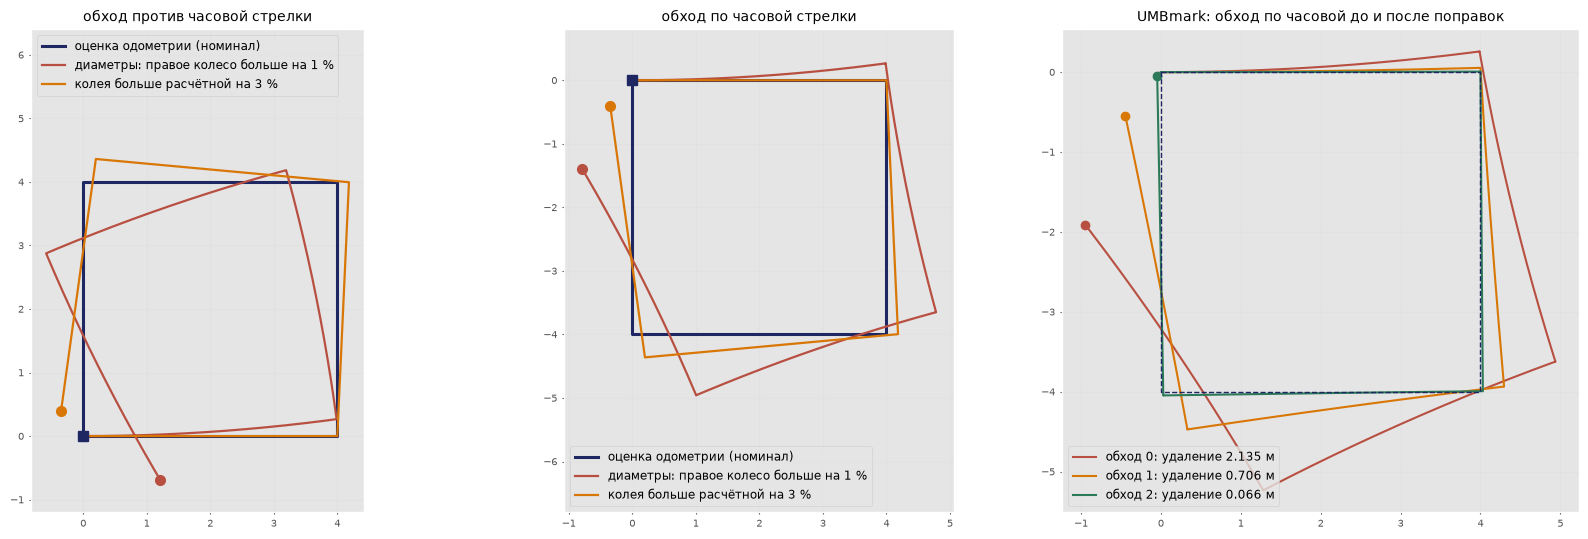

In [6]:
runs = {}
cases = (('диаметры: правое колесо больше на 1 %', (0.05*1.005, 0.05*0.995, 0.30)), ('колея больше расчётной на 3 %', (0.05, 0.05, 0.30*1.03)))
for nm, (rr, rl, bt) in cases:
    for ccw in (True, False):
        Pq = square_run(rr, rl, bt, ccw=ccw); runs[(nm, ccw)] = Pq
        print('%-38s %-15s конец = (%+.3f; %+.3f) м, удаление %.2f м, ошибка курса %+.1f°' % (nm, 'против часовой' if ccw else 'по часовой', Pq[-1, 0], Pq[-1, 1], np.hypot(*Pq[-1, :2]), deg(wrap(Pq[-1, 2]))))
Pd = runs[(cases[0][0], True)]
print('первая прямая 4 м при разнице диаметров: поворот %.3f рад = %.1f°, уход вбок %.2f м (оценка κs²/2 = %.2f м)' % (Pd[200, 2], deg(Pd[200, 2]), Pd[200, 1], 0.01/0.30*16/2))
print('ошибка колеи: каждый поворот на 90° выполняется на %.1f°, то есть короче на %.1f°' % (90/1.03, 90 - 90/1.03))

# UMBmark: обе ошибки сразу, итерации «обход — поправка — повторный обход»
rr, rl, bt = 0.05*1.005, 0.05*0.995, 0.30*1.03
Ed_t, Eb_t, hist = 1.0, 1.0, []
print('\nUMBmark при обеих ошибках (истина: r_R/r_L = %.4f, b = %.4f м):' % (rr/rl, bt))
for it in range(4):
    rrn, rln, bn = umbmark_model(Ed_t, Eb_t)
    ec = square_run(rr, rl, bt, ccw=True, b_nom=bn, rr_nom=rrn, rl_nom=rln); ew = square_run(rr, rl, bt, ccw=False, b_nom=bn, rr_nom=rrn, rl_nom=rln)
    um = umbmark(ew[-1], ec[-1]); hist.append((ec, ew))
    print('  обход %d: модель r_R/r_L = %.4f, b = %.4f м;  удаление: против часовой %.3f м, по часовой %.3f м;  α = %+.2f°, β = %+.2f° -> E_d = %.5f, E_b = %.4f'
          % (it, rrn/rln, bn, np.hypot(*ec[-1, :2]), np.hypot(*ew[-1, :2]), deg(um['alpha']), deg(um['beta']), um['E_d'], um['E_b']))
    Ed_t *= um['E_d']; Eb_t *= um['E_b']

fig, axs = plt.subplots(1, 3, figsize=(17, 5.4))
for ax, ccw in zip(axs[:2], (True, False)):
    sq = np.array([[0, 0], [4, 0], [4, 4], [0, 4], [0, 0]], float) * [1, 1 if ccw else -1]
    ax.plot(sq[:, 0], sq[:, 1], color=NAVY, lw=2.2, label='оценка одометрии (номинал)')
    for (nm, c_), Pq in runs.items():
        if c_ != ccw: continue
        col = RED if 'диаметры' in nm else AMB; ax.plot(Pq[:, 0], Pq[:, 1], color=col, lw=1.6, label=nm); ax.plot(Pq[-1, 0], Pq[-1, 1], 'o', color=col, ms=7, zorder=6)
    ax.plot(0, 0, 's', color=NAVY, ms=7); ax.set_aspect('equal'); ax.grid(alpha=.3); ax.set_ylim((-1.2, 6.4) if ccw else (-6.8, 0.8)); ax.legend(fontsize=8.5, loc='upper left' if ccw else 'lower left')
    ax.set_title('обход %s стрелки' % ('против часовой' if ccw else 'по часовой'), fontsize=10)
ax = axs[2]
for it, col in zip(range(3), (RED, AMB, GREEN)):
    ew = hist[it][1]; ax.plot(ew[:, 0], ew[:, 1], color=col, lw=1.5, label='обход %d: удаление %.3f м' % (it, np.hypot(*ew[-1, :2]))); ax.plot(ew[-1, 0], ew[-1, 1], 'o', color=col)
ax.plot([0, 4, 4, 0, 0], [0, 0, -4, -4, 0], color=NAVY, lw=1, ls='--'); ax.set_aspect('equal'); ax.grid(alpha=.3); ax.legend(fontsize=8.5, loc='lower left')
ax.set_title('UMBmark: обход по часовой до и после поправок', fontsize=10)
plt.tight_layout(); plt.show()

## 5. Реалистичная одометрия: неопределённость (§ 6.5, прил. 6.Б)

Случайные ошибки путей колёс за такт независимы, с нулевым средним и дисперсиями $\Sigma_\Delta=\operatorname{diag}(k_{\mathrm s}\lvert\Delta s_r\rvert,\ k_{\mathrm s}\lvert\Delta s_l\rvert)$. Ковариация позы на шаге средней точки: $\Sigma'=F_{\boldsymbol\xi}\Sigma F_{\boldsymbol\xi}^{\mathrm T}+F_\Delta\Sigma_\Delta F_\Delta^{\mathrm T}$ (функция `odo_cov_update`, якобианы — приложение 6.Б). Это шаг предсказания расширенного фильтра Калмана.
На прямой: $\sigma_\theta^2=cs$, $\sigma_y^2=cs^3/3$, $\sigma_x^2=k_{\mathrm s}s/2$, $c=2k_{\mathrm s}/b^2$. Для $k_{\mathrm s}=10^{-4}$ м (значение иллюстративное), $b=0{,}30$ м, шага 2 см и пути 4 м ожидаем $\sigma_x\approx0{,}014$ м, $\sigma_y\approx0{,}22$ м, $\sigma_\theta\approx5{,}4^{\circ}$; на 16 м $\sigma_y\approx1{,}7$ м; промежуточные точки рис. 6.6: $\sigma_y=0{,}027$ м на 1 м и $0{,}077$ м на 2 м. Монте-Карло на 2000 прогонах даёт продольный разброс больше линейной оценки: облако изгибается в «банан». Как на рис. 6.6 справа, изгиб хорошо виден на полуокружности радиуса 2 м при $k_{\mathrm s}=10^{-3}$ м (параметры иллюстративные): облако изогнуто, его среднее смещено от конца номинального пути, и эллипс его не описывает.
По желанию — целочисленный энкодер (1024 метки на оборот, опрос 50 Гц при 1 м/с, то есть те же 2 см за такт): счётчик накопительный, поэтому ошибка квантования не накапливается.

прямая  4.0 м: рекурсия σ_x = 0.0141, σ_y = 0.218 м, σ_θ = 5.40°;  формулы √(k_s s/2) = 0.0141, √(cs³/3) = 0.218 м, √(cs) = 5.40°
               Монте-Карло (2000): σ_x = 0.0172, σ_y = 0.219 м, σ_θ = 5.52°, среднее недоезжание (оценка впереди истины) 0.0087 м


прямая 16.0 м: рекурсия σ_x = 0.0283, σ_y = 1.742 м, σ_θ = 10.80°;  формулы √(k_s s/2) = 0.0283, √(cs³/3) = 1.742 м, √(cs) = 10.80°
               Монте-Карло (2000): σ_x = 0.1593, σ_y = 1.718 м, σ_θ = 10.73°, среднее недоезжание (оценка впереди истины) 0.1405 м
рост: σ_y(16)/σ_y(4) = 8.00 (s^{3/2} даёт 8), σ_x(16)/σ_x(4) по рекурсии = 2.00 (√s даёт 2)
σ_y по рекурсии на прямой: 1 м -> 0.027 м, 2 м -> 0.077 м, 4 м -> 0.218 м (при удвоении пути — в 2√2 = 2,83 раза)


продольный разброс Монте-Карло на 4 м для пяти зёрен генератора: 0.0172, 0.0177, 0.0178, 0.0172, 0.0176 м (линейная оценка 0,0141 м)
энкодер 1024 метки (метка 0.31 мм пути): σ_x = 0.0172, σ_y = 0.219 м; среднее смещается на 0.30 мм — ошибка квантования не накапливается


полуокружность ρ = 2 м, k_s = 1e-3 м: рекурсия σ_x = 0.914, σ_y = 0.526 м;  Монте-Карло σ_x = 0.862, σ_y = 0.500 м, среднее облака смещено на (+0.084; -0.139) м


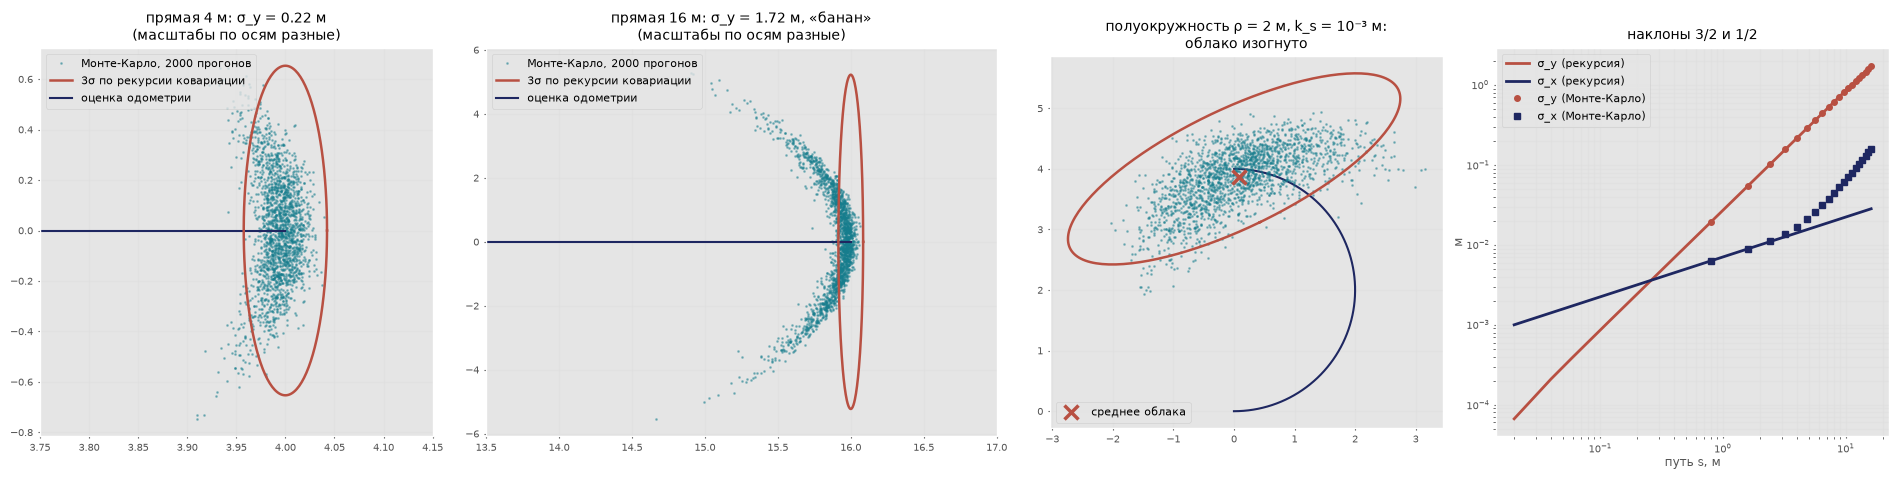

In [7]:
ks, b, ds = 1e-4, DD_B, 0.02
res = {}
for s_tot in (4.0, 16.0):
    nst = int(round(s_tot/ds)); dsr = dsl = np.full(nst, ds)
    Qc, Sc = odo_cov_path(dsr, dsl, b, ks); err = odo_monte_carlo(dsr, dsl, b, ks, 2000, seed=0); res[s_tot] = (Qc, Sc, err)
    e = err[:, -1]; c = 2*ks/b**2
    print('прямая %4.1f м: рекурсия σ_x = %.4f, σ_y = %.3f м, σ_θ = %.2f°;  формулы √(k_s s/2) = %.4f, √(cs³/3) = %.3f м, √(cs) = %.2f°'
          % (s_tot, np.sqrt(Sc[-1, 0, 0]), np.sqrt(Sc[-1, 1, 1]), deg(np.sqrt(Sc[-1, 2, 2])), np.sqrt(ks*s_tot/2), np.sqrt(c*s_tot**3/3), deg(np.sqrt(c*s_tot))))
    print('               Монте-Карло (2000): σ_x = %.4f, σ_y = %.3f м, σ_θ = %.2f°, среднее недоезжание (оценка впереди истины) %.4f м' % (e[:, 0].std(), e[:, 1].std(), deg(e[:, 2].std()), -e[:, 0].mean()))
print('рост: σ_y(16)/σ_y(4) = %.2f (s^{3/2} даёт 8), σ_x(16)/σ_x(4) по рекурсии = %.2f (√s даёт 2)' % (np.sqrt(res[16.0][1][-1, 1, 1]/res[4.0][1][-1, 1, 1]), np.sqrt(res[16.0][1][-1, 0, 0]/res[4.0][1][-1, 0, 0])))
print('σ_y по рекурсии на прямой: 1 м -> %.3f м, 2 м -> %.3f м, 4 м -> %.3f м (при удвоении пути — в 2√2 = 2,83 раза)' % tuple(np.sqrt(res[4.0][1][k, 1, 1]) for k in (50, 100, 200)))
nst = 200; d4 = np.full(nst, ds)
sx_seeds = [odo_monte_carlo(d4, d4, b, ks, 2000, seed=sd)[:, -1, 0].std() for sd in range(5)]
print('продольный разброс Монте-Карло на 4 м для пяти зёрен генератора: %s м (линейная оценка 0,0141 м)' % ', '.join('%.4f' % s_ for s_ in sx_seeds))
eT = odo_monte_carlo(d4, d4, b, ks, 2000, seed=0, ticks=1024)[:, -1]
print('энкодер 1024 метки (метка %.2f мм пути): σ_x = %.4f, σ_y = %.3f м; среднее смещается на %.2f мм — ошибка квантования не накапливается'
      % (2*np.pi*DD_R/1024*1e3, eT[:, 0].std(), eT[:, 1].std(), 1e3*(eT[:, 0].mean() - res[4.0][2][:, -1, 0].mean())))
rho_a, ks_a = 2.0, 1e-3; na = int(round(np.pi*rho_a/ds)); ar = np.full(na, ds*(1 + b/(2*rho_a))); al = np.full(na, ds*(1 - b/(2*rho_a)))
Qa, Sa = odo_cov_path(ar, al, b, ks_a); ea = odo_monte_carlo(ar, al, b, ks_a, 2000, seed=0)
print('полуокружность ρ = 2 м, k_s = 1e-3 м: рекурсия σ_x = %.3f, σ_y = %.3f м;  Монте-Карло σ_x = %.3f, σ_y = %.3f м, среднее облака смещено на (%+.3f; %+.3f) м'
      % (np.sqrt(Sa[-1, 0, 0]), np.sqrt(Sa[-1, 1, 1]), ea[:, -1, 0].std(), ea[:, -1, 1].std(), ea[:, -1, 0].mean(), ea[:, -1, 1].mean()))

fig, axs = plt.subplots(1, 4, figsize=(19, 4.8), gridspec_kw={'width_ratios': [1, 1.3, 1, 1]})
for ax, s_tot in zip(axs[:2], (4.0, 16.0)):
    Qc, Sc, err = res[s_tot]; e = err[:, -1]
    ax.plot(s_tot + e[:, 0], e[:, 1], '.', color=TEAL, ms=2, alpha=0.4, label='Монте-Карло, 2000 прогонов')
    draw_cov_ellipse(ax, Qc[-1], Sc[-1, :2, :2], 3.0, color=RED, label='3σ по рекурсии ковариации')
    ax.plot([0, s_tot], [0, 0], color=NAVY, lw=1.5, label='оценка одометрии'); ax.grid(alpha=.3); ax.legend(fontsize=8, loc='upper left')
    ax.set_xlim(s_tot - (0.25 if s_tot < 5 else 2.5), s_tot + (0.15 if s_tot < 5 else 1.0))
    ax.set_title('прямая %.0f м: σ_y = %.2f м%s\n(масштабы по осям разные)' % (s_tot, e[:, 1].std(), ', «банан»' if s_tot > 5 else ''), fontsize=10)
ax = axs[2]; ax.plot(Qa[:, 0], Qa[:, 1], color=NAVY, lw=1.5)
ax.plot(Qa[-1, 0] + ea[:, -1, 0], Qa[-1, 1] + ea[:, -1, 1], '.', color=TEAL, ms=2, alpha=0.4); draw_cov_ellipse(ax, Qa[-1], Sa[-1, :2, :2], 3.0, color=RED)
ax.plot(Qa[-1, 0] + ea[:, -1, 0].mean(), Qa[-1, 1] + ea[:, -1, 1].mean(), 'x', color=RED, ms=10, mew=2.5, label='среднее облака'); ax.legend(fontsize=8, loc='lower left')
ax.set_aspect('equal'); ax.grid(alpha=.3); ax.set_title('полуокружность ρ = 2 м, k_s = 10⁻³ м:\nоблако изогнуто', fontsize=10)
ax = axs[3]; Qc, Sc, err = res[16.0]; s_ = np.arange(len(Sc))*ds; sel = s_ > 0
ax.loglog(s_[sel], np.sqrt(Sc[sel, 1, 1]), color=RED, lw=2, label='σ_y (рекурсия)'); ax.loglog(s_[sel], np.sqrt(Sc[sel, 0, 0]), color=NAVY, lw=2, label='σ_x (рекурсия)')
idx = np.arange(40, len(s_), 40)
ax.loglog(s_[idx], err[:, idx, 1].std(0), 'o', color=RED, ms=4, label='σ_y (Монте-Карло)'); ax.loglog(s_[idx], err[:, idx, 0].std(0), 's', color=NAVY, ms=4, label='σ_x (Монте-Карло)')
ax.set_xlabel('путь s, м'); ax.set_ylabel('м'); ax.grid(alpha=.3, which='both'); ax.legend(fontsize=8); ax.set_title(r'наклоны $3/2$ и $1/2$', fontsize=10)
plt.tight_layout(); plt.show()

## 6. Трицикл и автомобиль (§ 6.6, пример 6.4, прил. 6.Д)

Трицикл: $\rho=d/\operatorname{tg}\delta$; привод на рулевом колесе — $v=v_s\cos\delta$, $\omega=v_s\sin\delta/d$; привод на задней оси (велосипедная модель) — $\omega=v\operatorname{tg}\delta/d$.
Аккерман: $\operatorname{tg}\delta_i=\dfrac{d}{\rho-b/2}$, $\operatorname{tg}\delta_o=\dfrac{d}{\rho+b/2}$, $\operatorname{ctg}\delta_o-\operatorname{ctg}\delta_i=b/d$. Ожидаем при $d=2{,}7$, $b=1{,}6$, $\rho=6$ м: $\delta_i=27{,}4^\circ$, $\delta_o=21{,}7^\circ$, $\delta=24{,}2^\circ$, задние колёса $1:1{,}31$.
**Сломай и посмотри:** оба передних колеса повёрнуты на одинаковый угол $24{,}2^\circ$. Оси колёс уже не сходятся в одной точке, $\operatorname{rank}C_1=3$; считаем, какое колесо и с какой скоростью скользит вбок, если задняя ось катится без скольжения по дуге $\rho=6$ м. *Вопрос к опыту:* почему скользят оба передних колеса, причём с равными и противоположными скоростями, и как скорость скольжения зависит от скорости движения?
Сверка с `rtb.Bicycle(L = 2,7)`: $\dot\theta=\operatorname{tg}0{,}42/2{,}7=0{,}1654$ рад/с при $v=1$ м/с. Ещё два числа приложения 6.Д и § 6.9: модель центра масс и предел сцепления.

пример 6.4: δ_i = 27.4°, δ_o = 21.7°, эквивалентный трицикл δ = 24.2°
условие Аккермана: ctg δ_o − ctg δ_i = 0.593, b/d = 0.593
задние колёса: радиусы 5.2 и 6.8 м, отношение скоростей = 1 : 1.31
ранг C_1: углы Аккермана — 2 (МЦВ существует), одинаковые углы 24,2° — 3 (общего МЦВ нет)
скорости скольжения колёс вдоль их осей (ЗЛ, ЗП, ПЛ, ПП) при v = 1 м/с, ρ = 6 м:
   Аккерман:         [ 0.  0. -0.  0.] м/с
   одинаковые углы:  [ 0.      0.      0.0547 -0.0547] м/с: внутреннее переднее колесо требует 27,4°, наружное 21,7°, оба скользят
трицикл d = 1,2 м, руль 30°, скорость 1 м/с: ρ = 2.078 м; передний привод (v, ω) = (0.866; 0.417), задний привод (1.000; 0.481)
центр масс (d_f = 1,2, d_r = 1,5 м, δ = 10°): β_c = 5.6°, ρ задней оси = 15.31 м, ρ центра масс = 15.39 м
предел сцепления на дуге ρ = 6 м при μ = 0,8: v ≤ √(μgρ) = 6.9 м/с
rtb.Bicycle(L = 2,7).deriv(ξ = 0, u = (1; 0,42)) = [1.     0.     0.1654];  tri_rear: ω = 0.1654;  tg(0,42)/2,7 = 0.1654


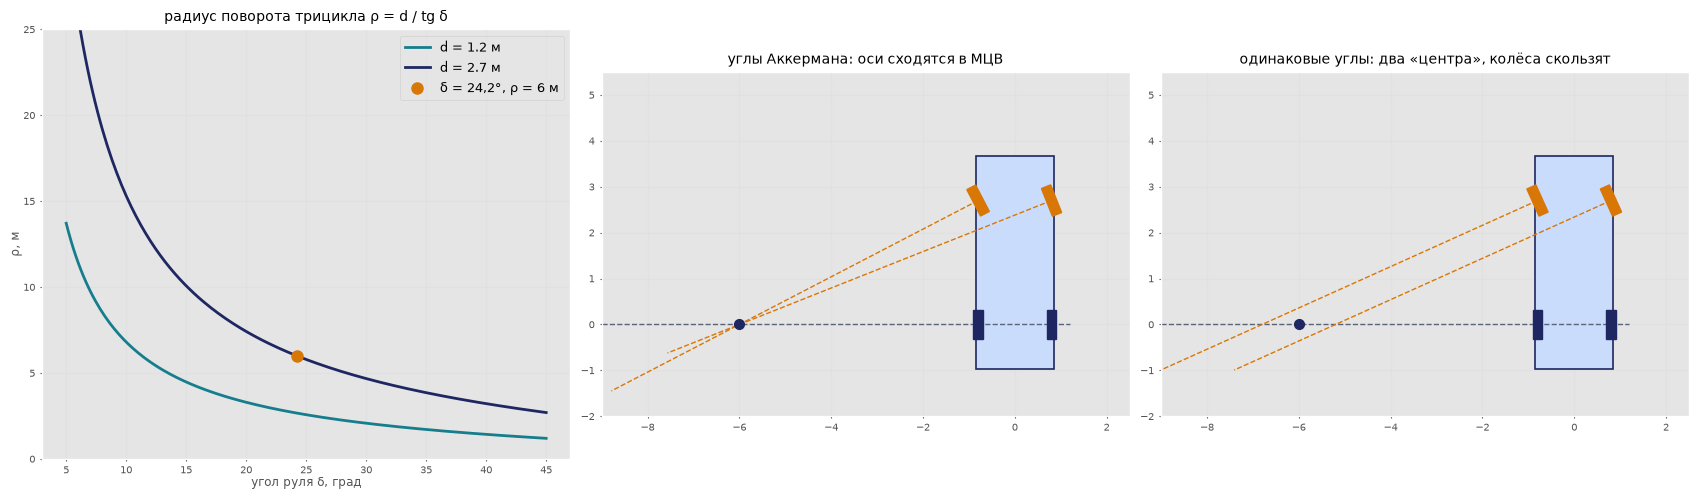

In [8]:
R0 = 6.0; di, do, de = ackermann(R0); Vi, Vo = rear_wheel_speeds(1.0, R0, ACK_B)
print('пример 6.4: δ_i = %.1f°, δ_o = %.1f°, эквивалентный трицикл δ = %.1f°' % (deg(di), deg(do), deg(de)))
print('условие Аккермана: ctg δ_o − ctg δ_i = %.3f, b/d = %.3f' % (1/np.tan(do) - 1/np.tan(di), ACK_B/ACK_D))
print('задние колёса: радиусы %.1f и %.1f м, отношение скоростей = 1 : %.2f' % (R0 - ACK_B/2, R0 + ACK_B/2, Vo/Vi))
rear = [wheel_at(0.0, ACK_B/2), wheel_at(0.0, -ACK_B/2)]
C_ok = maneuverability(rear, [wheel_at(ACK_D, ACK_B/2, di), wheel_at(ACK_D, -ACK_B/2, do)])
C_bad = maneuverability(rear, [wheel_at(ACK_D, ACK_B/2, de), wheel_at(ACK_D, -ACK_B/2, de)])
u = np.array([1.0, 0.0, 1.0/R0])                         # задняя ось без скольжения, v = 1 м/с, ρ = 6 м
print('ранг C_1: углы Аккермана — %d (МЦВ существует), одинаковые углы 24,2° — %d (общего МЦВ нет)' % (C_ok[1], C_bad[1]))
print('скорости скольжения колёс вдоль их осей (ЗЛ, ЗП, ПЛ, ПП) при v = 1 м/с, ρ = 6 м:')
print('   Аккерман:        ', (C_ok[0].dot(u) + 0.0).round(4), 'м/с')
print('   одинаковые углы: ', (C_bad[0].dot(u) + 0.0).round(4), 'м/с: внутреннее переднее колесо требует 27,4°, наружное 21,7°, оба скользят')
vs, dl, dtri = 1.0, rad(30.0), 1.2
print('трицикл d = 1,2 м, руль 30°, скорость 1 м/с: ρ = %.3f м; передний привод (v, ω) = (%.3f; %.3f), задний привод (%.3f; %.3f)' % ((dtri/np.tan(dl),) + tri_front(vs, dl, dtri) + tri_rear(vs, dl, dtri)))
bc, wc, rc = bicycle_cm(1.0, rad(10.0), 1.2, 1.5)
print('центр масс (d_f = 1,2, d_r = 1,5 м, δ = 10°): β_c = %.1f°, ρ задней оси = %.2f м, ρ центра масс = %.2f м' % (deg(bc), 2.7/np.tan(rad(10.0)), rc))
print('предел сцепления на дуге ρ = 6 м при μ = 0,8: v ≤ √(μgρ) = %.1f м/с' % np.sqrt(0.8*9.81*6.0))
if rtb is not None:
    car = rtb.Bicycle(L=2.7); xd = car.deriv(np.zeros(3), [1.0, 0.42])
    print('rtb.Bicycle(L = 2,7).deriv(ξ = 0, u = (1; 0,42)) = %s;  tri_rear: ω = %.4f;  tg(0,42)/2,7 = %.4f' % (xd.round(4), tri_rear(1.0, 0.42, 2.7)[1], np.tan(0.42)/2.7))

fig, axs = plt.subplots(1, 3, figsize=(17, 5))
ax = axs[0]; ds_ = np.linspace(rad(5), rad(45), 200)
for dd_, col in ((1.2, TEAL), (ACK_D, NAVY)): ax.plot(deg(ds_), dd_/np.tan(ds_), color=col, lw=2, label='d = %.1f м' % dd_)
ax.plot(deg(de), R0, 'o', color=AMB, ms=8, label='δ = 24,2°, ρ = 6 м'); ax.set_xlabel('угол руля δ, град'); ax.set_ylabel('ρ, м'); ax.set_ylim(0, 25); ax.grid(alpha=.3); ax.legend(fontsize=9)
ax.set_title('радиус поворота трицикла ρ = d / tg δ', fontsize=10)
for ax, (dL, dR, ttl) in zip(axs[1:], ((di, do, 'углы Аккермана: оси сходятся в МЦВ'), (de, de, 'одинаковые углы: два «центра», колёса скользят'))):
    q0 = np.array([0.0, 0.0, np.pi/2]); draw_car(ax, q0, di=dL, do=dR); icc = np.array([-R0, 0.0])
    ax.plot([-9, 1.2], [0, 0], color=GREY, lw=1, ls='--')
    for (px, py, a_) in ((ACK_D, ACK_B/2, dL), (ACK_D, -ACK_B/2, dR)):
        pw = np.array([-py, px]); ang = np.pi/2 + a_ + np.pi/2; L_ = 9.0
        ax.plot([pw[0], pw[0] + L_*np.cos(ang)], [pw[1], pw[1] + L_*np.sin(ang)], color=AMB, lw=1, ls='--')
    ax.plot(icc[0], icc[1], 'o', color=NAVY, ms=7); ax.set_xlim(-9, 2.5); ax.set_ylim(-2, 5.5); ax.set_aspect('equal'); ax.grid(alpha=.3); ax.set_title(ttl, fontsize=10)
plt.tight_layout(); plt.show()

## 7. Трёхколёсная омни-платформа (§ 6.7, пример 6.5)

Из связей сразу получается обратная задача: $r\dot\varphi_i=-\sin\alpha_i\,v_x+\cos\alpha_i\,v_y+l\omega$, $\dot{\boldsymbol\varphi}=H\dot{\boldsymbol\xi}_R$; прямая — обращением $H$. Строка $H$ — направление тяги $\mathbf t_i$ и его момент относительно $P$, делённые на $r$, то есть координаты **линии тяги** колеса.
Ожидаем при $r=0{,}05$, $l=0{,}20$ м, $\dot{\boldsymbol\xi}_R=(0{,}2;\ 0{,}1;\ 0{,}5)$: $\dot{\boldsymbol\varphi}=(4{,}00;\ -2{,}46;\ 4{,}46)$ рад/с, $\det H=3\sqrt3\,l/(2r^3)=4156{,}9$; при движении вперёд первое колесо стоит.
**Сломай и посмотри:** колёса повёрнуты так, что тяга идёт по радиусам. Линии тяги проходят через центр, третий столбец $H$ нулевой, $\det H=0$: вращение вокруг центра вообще не требует вращения колёс и не управляется. Оси колёс при этом не важны: в схеме $120^\circ$ они как раз все проходят через центр, а $H$ невырождена. Две параллельные линии тяги из трёх допустимы. *Вопрос к опыту:* какое движение корпуса платформа с тягой по радиусам выполнить не может и что покажут энкодеры, если её повернуть вокруг центра рукой?
Затем — движение по прямой с вращением: скорости колёс меняются по гармоническому закону.

H =
 [[  0.      20.       4.    ]
 [-17.3205 -10.       4.    ]
 [ 17.3205 -10.       4.    ]] 
det H = 4156.9,  3√3·l/(2r³) = 4156.9
F = H⁻¹ =
 [[ 0.     -0.0289  0.0289]
 [ 0.0333 -0.0167 -0.0167]
 [ 0.0833  0.0833  0.0833]]
пример 6.5: φ̇ = [ 4.   -2.46  4.46] рад/с;  обратно ξ̇_R = H⁻¹φ̇ = [0.2 0.1 0.5]
чистое движение вперёд ξ̇_R = (0,3; 0; 0): φ̇ = [ 0.    -5.196  5.196]  (первое колесо стоит, √3 v/(2r) = 5.196)
H по линиям тяги совпадает с omni_H: max|Δ| = 4.4e-16

сломай: тяга по радиусам ->  H =
 [[ 20.       0.       0.    ]
 [-10.      17.3205   0.    ]
 [-10.     -17.3205  -0.    ]] 
  det H = -9.6e-14, rank H = 2, H·(0; 0; 1) = [ 0.  0. -0.] — поворот вокруг центра колёса «не видят»
  две линии тяги параллельны, третья их пересекает: det H = -3200 — невырождена


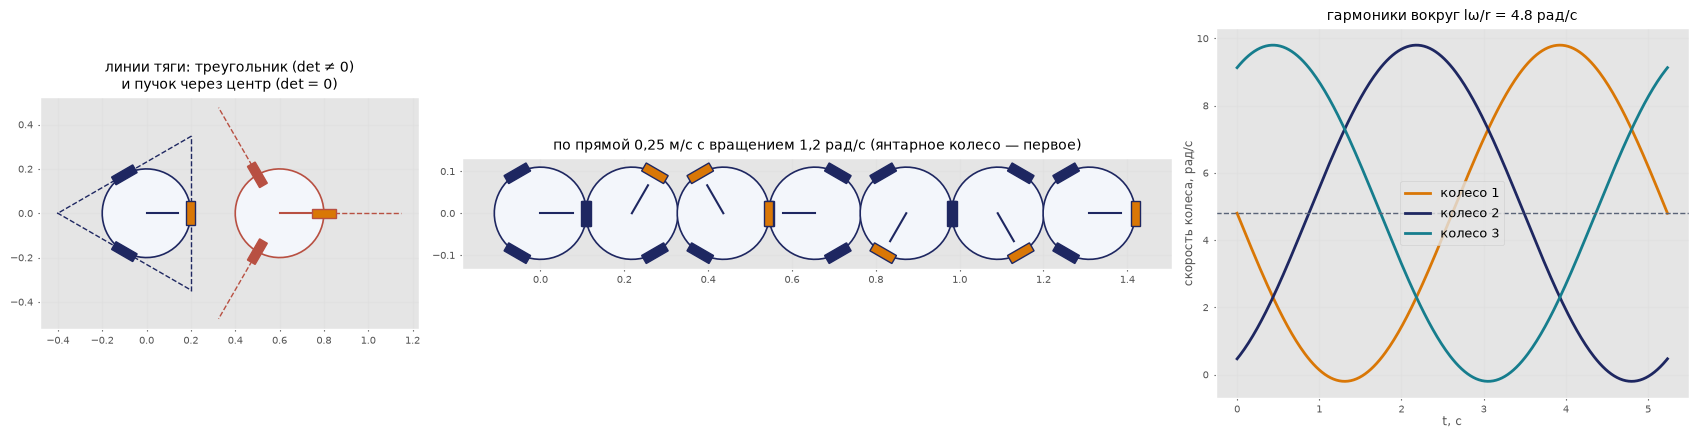

In [9]:
H = omni_H(); u = np.array([0.2, 0.1, 0.5]); phi = H.dot(u)
print('H =\n', H + 0.0, '\ndet H = %.1f,  3√3·l/(2r³) = %.1f' % (np.linalg.det(H), 3*np.sqrt(3)*OMNI_L/(2*OMNI_R**3)))
print('F = H⁻¹ =\n', np.linalg.inv(H))
print('пример 6.5: φ̇ =', phi.round(2), 'рад/с;  обратно ξ̇_R = H⁻¹φ̇ =', np.linalg.solve(H, phi).round(4))
print('чистое движение вперёд ξ̇_R = (0,3; 0; 0): φ̇ =', (H.dot([0.3, 0, 0]) + 0.0).round(3), ' (первое колесо стоит, √3 v/(2r) = %.3f)' % (np.sqrt(3)*0.3/(2*OMNI_R)))
pts = [(OMNI_L*np.cos(a), OMNI_L*np.sin(a)) for a in OMNI_ALPHA]
H_t = omni_H_lines(pts, [(-np.sin(a), np.cos(a)) for a in OMNI_ALPHA]); print('H по линиям тяги совпадает с omni_H: max|Δ| = %.1e' % np.abs(H_t - H).max())
H_r = omni_H_lines(pts, [(np.cos(a), np.sin(a)) for a in OMNI_ALPHA])
print('\nсломай: тяга по радиусам ->  H =\n', H_r + 0.0, '\n  det H = %.1e, rank H = %d, H·(0; 0; 1) = %s — поворот вокруг центра колёса «не видят»' % (np.linalg.det(H_r), np.linalg.matrix_rank(H_r), (H_r.dot([0, 0, 1.0]) + 0.0).round(3)))
H_p = omni_H_lines([(0.2, 0.0), (-0.2, 0.0), (0.0, 0.2)], [(0, 1), (0, 1), (1, 0)])
print('  две линии тяги параллельны, третья их пересекает: det H = %.0f — невырождена' % np.linalg.det(H_p))

qd = np.array([0.25, 0.0, 1.2]); T = 2*np.pi/qd[2]; ts = np.linspace(0, T, 300)
ph = np.array([H.dot(rotz(qd[2]*t).T.dot(qd)) for t in ts])
fig, axs = plt.subplots(1, 3, figsize=(17, 4.4), gridspec_kw={'width_ratios': [0.8, 1.5, 1]})
ax = axs[0]
for H_, ang, col, lab in ((H, None, NAVY, 'тяга по касательной'), (H_r, OMNI_ALPHA, RED, 'тяга по радиусам')):
    draw_omni3(ax, np.array([0.0 if ang is None else 0.6, 0.0, 0.0]), scale=1.0, wheel_ang=ang, color=col)
    for p, t_ in zip(pts, ([(-np.sin(a), np.cos(a)) for a in OMNI_ALPHA] if ang is None else [(np.cos(a), np.sin(a)) for a in OMNI_ALPHA])):
        x0 = (0.0 if ang is None else 0.6) + p[0]; ax.plot([x0 - 0.35*t_[0], x0 + 0.35*t_[0]], [p[1] - 0.35*t_[1], p[1] + 0.35*t_[1]], color=col, lw=1, ls='--')
ax.set_aspect('equal'); ax.grid(alpha=.3); ax.set_title('линии тяги: треугольник (det ≠ 0)\nи пучок через центр (det = 0)', fontsize=10)
ax = axs[1]; ax.plot(qd[0]*ts, 0*ts, color=RED, lw=1.5)
for t in np.linspace(0, T, 7): draw_omni3(ax, np.array([qd[0]*t, 0.0, qd[2]*t]), scale=0.55)
ax.set_aspect('equal'); ax.grid(alpha=.3); ax.set_title('по прямой 0,25 м/с с вращением 1,2 рад/с (янтарное колесо — первое)', fontsize=10)
ax = axs[2]
for i, col in enumerate((AMB, NAVY, TEAL)): ax.plot(ts, ph[:, i], color=col, lw=2, label='колесо %d' % (i + 1))
ax.axhline(OMNI_L*qd[2]/OMNI_R, color=GREY, ls='--', lw=1); ax.set_xlabel('t, с'); ax.set_ylabel('скорость колеса, рад/с'); ax.grid(alpha=.3); ax.legend(fontsize=9)
ax.set_title('гармоники вокруг lω/r = %.1f рад/с' % (OMNI_L*qd[2]/OMNI_R), fontsize=10)
plt.tight_layout(); plt.show()

## 8. Меканум-платформа (§ 6.8, примеры 6.6, 6.7)

$r\dot\varphi_{1,4}=v_x-v_y\mp(l_x+l_y)\omega$, $r\dot\varphi_{2,3}=v_x+v_y\pm(l_x+l_y)\omega$ (колёса: 1 — ПЛ, 2 — ПП, 3 — ЗЛ, 4 — ЗП); прямая задача — псевдообратной $F=H^{+}=(H^{\mathrm T}H)^{-1}H^{\mathrm T}$; условие совместности $\dot\varphi_1+\dot\varphi_2-\dot\varphi_3-\dot\varphi_4=0$.
Ожидаем ($r=0{,}05$, $l_x=0{,}235$, $l_y=0{,}15$ м): пример 6.6 — $\dot{\boldsymbol\xi}_R=(0{,}3;\ 0{,}2;\ 0{,}5)\to\dot{\boldsymbol\varphi}=(-1{,}85;\ 13{,}85;\ 6{,}15;\ 5{,}85)$; пример 6.7 — невязка совместности $0{,}6$ рад/с, $\dot{\boldsymbol\xi}_R\approx(0{,}503;\ -0{,}0025;\ 0{,}032)$, остаток $0{,}15\cdot(1,1,-1,-1)$; октаэдр при $\dot\varphi_{\max}=20$ рад/с: 1 м/с вперёд, $0{,}71$ м/с по диагонали, $2{,}6$ рад/с.
**Сломай и посмотри:** колёса переставлены так, что рисунок X образуют нижние ролики. Знаки $\gamma_i$ меняются, в третьем столбце вместо $l_x+l_y$ стоит $l_x-l_y$. Ранг остаётся 3, сингулярные числа $(40;\ 40;\ 3{,}4)$ вместо $(40;\ 40;\ 15{,}4)$, плечо момента сил роликов $0{,}060$ м вместо $0{,}27$ м, а СКО оценки $\omega$ по энкодерам в $4{,}5$ раза больше. При $l_x=l_y$ ранг падает до двух. *Вопрос к опыту:* почему поворот переставленной платформы плохо управляем, хотя ранг $H$ по-прежнему равен трём и колёсам даже нужно вращаться медленнее?

H =
 [[ 20.  -20.   -7.7]
 [ 20.   20.    7.7]
 [ 20.   20.   -7.7]
 [ 20.  -20.    7.7]] 
HᵀH = diag [1600.  1600.   237.2] ;  max|H⁺ − pinv(H)| = 1.4e-17;  H из геометрии роликов: max|Δ| = 3.6e-15

базовые движения (скорости колёс 1..4, рад/с):
  вперёд                     ξ̇_R = (0.3, 0, 0)      φ̇ = [6. 6. 6. 6.]
  влево                      ξ̇_R = (0, 0.3, 0)      φ̇ = [-6.  6.  6. -6.]
  вправо                     ξ̇_R = (0, -0.3, 0)     φ̇ = [ 6. -6. -6.  6.]
  диагональ вперёд-влево     ξ̇_R = (0.3, 0.3, 0)    φ̇ = [ 0. 12. 12.  0.]
  диагональ вперёд-вправо    ξ̇_R = (0.3, -0.3, 0)   φ̇ = [12.  0.  0. 12.]
  поворот против часовой     ξ̇_R = (0, 0, 1.0)      φ̇ = [-7.7  7.7 -7.7  7.7]

пример 6.6: φ̇ = [-1.85 13.85  6.15  5.85] ;  совместность = 0.0e+00;  обратно ξ̇_R = [0.3 0.2 0.5] ;  φ̇₂/|φ̇₁| = 7.5
пример 6.7: совместность = 0.6 рад/с;  ξ̇_R = (0.5025; -0.0025; 0.0325);  невязка = [ 0.15  0.15 -0.15 -0.15] рад/с
октаэдр при φ̇_max = 20 рад/с: вперёд 1.00 м/с, по диагонали 

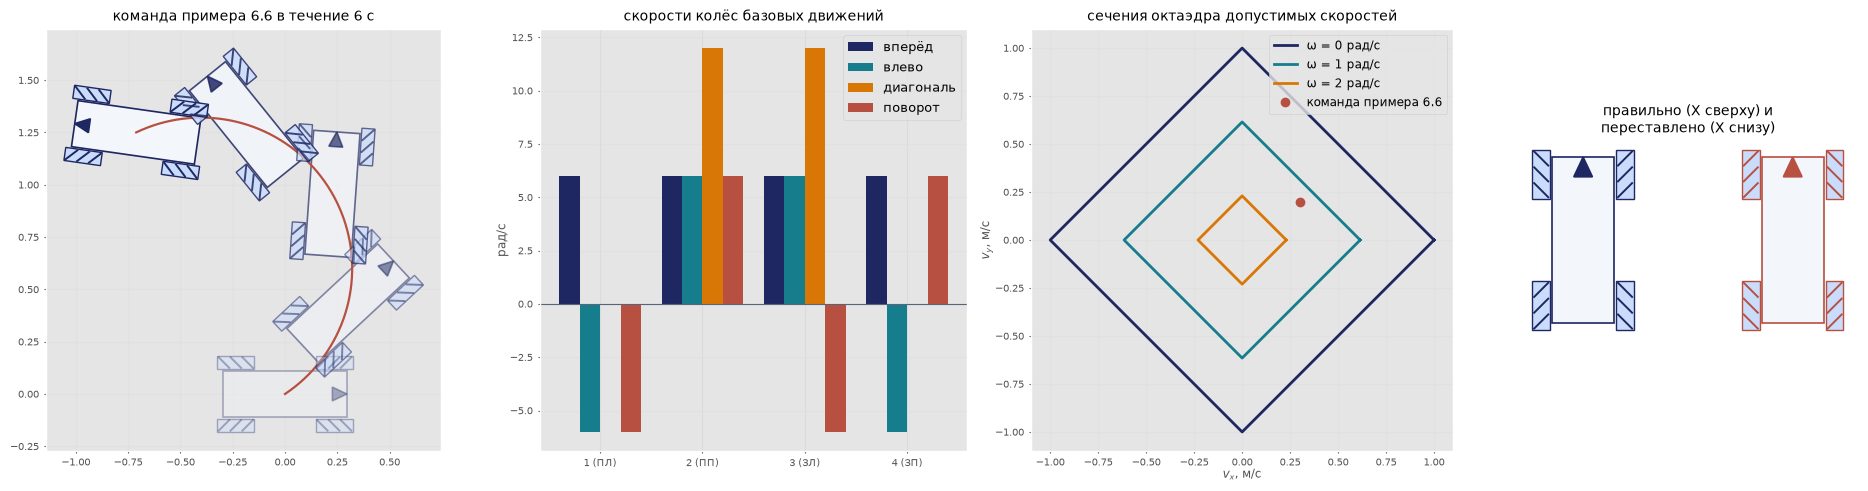

In [10]:
H = mec_H(); Hp = mec_Hpinv()
print('H =\n', H, '\nHᵀH = diag', np.diag(H.T.dot(H)).round(1), ';  max|H⁺ − pinv(H)| = %.1e;  H из геометрии роликов: max|Δ| = %.1e' % (np.abs(Hp - np.linalg.pinv(H)).max(), np.abs(mec_H_rollers() - H).max()))
print('\nбазовые движения (скорости колёс 1..4, рад/с):')
for nm, u in (('вперёд', (0.3, 0, 0)), ('влево', (0, 0.3, 0)), ('вправо', (0, -0.3, 0)), ('диагональ вперёд-влево', (0.3, 0.3, 0)), ('диагональ вперёд-вправо', (0.3, -0.3, 0)), ('поворот против часовой', (0, 0, 1.0))):
    print('  %-26s ξ̇_R = %-16s φ̇ = %s' % (nm, str(u), H.dot(u).round(2) + 0.0))
u66 = np.array([0.3, 0.2, 0.5]); phi66 = H.dot(u66); u_back, res, comp = mec_fk(phi66)
print('\nпример 6.6: φ̇ =', phi66.round(2), ';  совместность = %.1e;  обратно ξ̇_R =' % comp, u_back.round(4), ';  φ̇₂/|φ̇₁| = %.1f' % (phi66[1]/abs(phi66[0])))
u67, res67, comp67 = mec_fk([10.0, 10.4, 9.6, 10.2])
print('пример 6.7: совместность = %.1f рад/с;  ξ̇_R = (%.4f; %.4f; %.4f);  невязка =' % ((comp67,) + tuple(u67)), res67.round(3), 'рад/с')
print('октаэдр при φ̇_max = 20 рад/с: вперёд %.2f м/с, по диагонали %.2f м/с, поворот %.2f рад/с; команда 6.6: |v_x| + |v_y| + (l_x + l_y)|ω| = %.2f м/с при пределе %.2f'
      % (mec_vmax(0.0), mec_vmax(np.pi/4), MEC_R*20/(MEC_LX + MEC_LY), 0.3 + 0.2 + (MEC_LX + MEC_LY)*0.5, MEC_R*20))

H_bad = mec_H_rollers(rad([45.0, -45.0, -45.0, 45.0]))        # «X снизу»: знаки всех γ_i сменились
sv, sv_bad = np.linalg.svd(H, compute_uv=False), np.linalg.svd(H_bad, compute_uv=False)
print('\nсломай: колёса переставлены, r·H =\n', MEC_R*H_bad)
print('  rank = %d; сингулярные числа правильной установки %s, переставленной %s' % (np.linalg.matrix_rank(H_bad), sv.round(1), sv_bad.round(1)))
print('  плечо момента сил роликов: (l_x + l_y)/√2 = %.3f м -> (l_x − l_y)/√2 = %.3f м' % ((MEC_LX + MEC_LY)/np.sqrt(2), (MEC_LX - MEC_LY)/np.sqrt(2)))
sig = 0.1; s_ok = sig*np.linalg.norm(np.linalg.pinv(H)[2]); s_bad = sig*np.linalg.norm(np.linalg.pinv(H_bad)[2])
print('  СКО оценки ω при шуме энкодеров %.1f рад/с: %.4f -> %.4f рад/с, в %.1f раза больше' % (sig, s_ok, s_bad, s_bad/s_ok))
print('  кинематический предел ω при φ̇_max = 20: %.1f -> %.1f рад/с (колёсам вращаться даже легче, но момента почти нет)' % (MEC_R*20/(MEC_LX + MEC_LY), MEC_R*20/(MEC_LX - MEC_LY)))
H_sq = mec_H_rollers(rad([45.0, -45.0, -45.0, 45.0]), lx=0.2, ly=0.2)
print('  квадратная платформа l_x = l_y = 0,2 м: rank = %d, сингулярные числа %s — поворот не связан со скоростями колёс' % (np.linalg.matrix_rank(H_sq), np.linalg.svd(H_sq, compute_uv=False).round(1)))

fig, axs = plt.subplots(1, 4, figsize=(19, 4.8), gridspec_kw={'width_ratios': [1.1, 1, 1, 0.8]})
ax = axs[0]; Pm = simulate_body(lambda t: u66, T=6.0, n=300); draw_path(ax, Pm)
for k in (0, 75, 150, 225, 300): draw_mecanum(ax, Pm[k], alpha=0.35 + 0.65*k/300)
ax.set_aspect('equal'); ax.grid(alpha=.3); ax.set_title('команда примера 6.6 в течение 6 с', fontsize=10)
ax = axs[1]; lab = ['вперёд', 'влево', 'диагональ', 'поворот']; us = [(0.3, 0, 0), (0, 0.3, 0), (0.3, 0.3, 0), (0, 0, 0.78)]; wdt = 0.2
for i, u in enumerate(us):
    ax.bar(np.arange(4) + i*wdt - 0.3, H.dot(u), wdt, color=(NAVY, TEAL, AMB, RED)[i], label=lab[i])
ax.axhline(0, color=GREY, lw=.8); ax.set_xticks(range(4)); ax.set_xticklabels(['1 (ПЛ)', '2 (ПП)', '3 (ЗЛ)', '4 (ЗП)']); ax.set_ylabel('рад/с'); ax.grid(alpha=.3, axis='y'); ax.legend(fontsize=9)
ax.set_title('скорости колёс базовых движений', fontsize=10)
ax = axs[2]; aa = np.linspace(0, 2*np.pi, 361)
for om, col in ((0.0, NAVY), (1.0, TEAL), (2.0, AMB)):
    rr = np.array([mec_vmax(a_, om) for a_ in aa]); ax.plot(rr*np.cos(aa), rr*np.sin(aa), color=col, lw=2, label='ω = %.0f рад/с' % om)
ax.plot(0.3, 0.2, 'o', color=RED, label='команда примера 6.6'); ax.set_aspect('equal'); ax.grid(alpha=.3); ax.legend(fontsize=8.5, loc='upper right'); ax.set_xlabel(r'$v_x$, м/с'); ax.set_ylabel(r'$v_y$, м/с')
ax.set_title('сечения октаэдра допустимых скоростей', fontsize=10)
ax = axs[3]; draw_mecanum(ax, np.array([0.0, 0.0, np.pi/2])); draw_mecanum(ax, np.array([0.75, 0.0, np.pi/2]), top=(-1, 1, 1, -1), color=RED)
ax.set_aspect('equal'); ax.axis('off'); ax.set_title('правильно (X сверху) и\nпереставлено (X снизу)', fontsize=10)
plt.tight_layout(); plt.show()

## 9. Ранг $C_1$ и манёвренность (§ 6.9, прил. 6.Д)

Строка запрета бокового скольжения колеса с параметрами $(\alpha,\beta,l)$: $\big(\cos(\alpha+\beta),\ \sin(\alpha+\beta),\ l\sin\beta\big)$ — каждая строка требует, чтобы МЦВ лежал на оси колеса. $C_1$ собирается из строк фиксированных и рулевых колёс; $\delta_m=3-\operatorname{rank}C_1$, $\delta_s=\operatorname{rank}C_{1s}$, $\delta_M=\delta_m+\delta_s$.
Ожидаем пять типов $(3,0)$, $(2,0)$, $(2,1)$, $(1,1)$, $(1,2)$; тележка с тремя фиксированными колёсами, оси которых образуют треугольник, — rank 3, $\delta_m=0$; шасси с бортовым поворотом (четыре фиксированных колеса) — rank 2, $\delta_m=1$: без проскальзывания только прямая. Практическая модель бортового поворота $\omega=(V_r-V_l)/(\chi b)$: при $b=0{,}5$ м и $\chi=1{,}5$ (иллюстративно) номинальные $\pm0{,}25$ м/с дают $0{,}67$ рад/с вместо 1, нужны $\pm0{,}375$ м/с. Поворотные модули (тип $(1,2)$, приложение 6.Д): при модулях в $(\pm0{,}3;\ \pm0{,}25)$ м и команде $(0{,}5;\ 0;\ 1{,}0)$ передний левый модуль — $50{,}2^\circ$ и $0{,}39$ м/с, передний правый — $21{,}8^\circ$ и $0{,}81$ м/с.

In [11]:
print('связи колёс дифференциальной схемы (l = b/2 = 0,15 м):')
for nm, w_ in (('левое', wheel_at(0.0, DD_B/2)), ('правое', wheel_at(0.0, -DD_B/2))):
    print('  %-7s α = %+5.0f°, β = %4.0f°;  качение: %s·ξ̇_R = rφ̇;  скольжение: %s·ξ̇_R = 0' % (nm, deg(w_[0]), deg(w_[1]) % 360, (roll_row(*w_) + 0.0).round(3), (slide_row(*w_) + 0.0).round(3)))
print('шведское колесо при γ = 0 совпадает с условием качения:', np.allclose(swedish_row(0.3, 0.4, 0.0, 0.2), roll_row(0.3, 0.4, 0.2)))

dl = rad(25.0); chassis = [
    ('омни- или меканум-платформа',               [], []),
    ('дифференциальная схема',                    [wheel_at(0, 0.15), wheel_at(0, -0.15)], []),
    ('одно рулевое колесо и пассивные опоры',     [], [wheel_at(0.2, 0, dl)]),
    ('трицикл (велосипед, автомобиль)',           [wheel_at(0, 0.3), wheel_at(0, -0.3)], [wheel_at(1.2, 0, dl)]),
    ('два независимых рулевых колеса',            [], [wheel_at(0.4, 0, dl), wheel_at(-0.4, 0, -rad(15.0))]),
    ('три фиксированных колеса, оси — треугольник', [(a, np.pi/2, 0.3) for a in (0, 2*np.pi/3, 4*np.pi/3)], []),
    ('бортовой поворот: 4 фиксированных колеса',   [wheel_at(x, y) for x in (0.25, -0.25) for y in (0.2, -0.2)], []),
]
print('\n%-46s %7s %8s %8s %8s' % ('шасси', 'rank C1', 'δ_m', 'δ_s', 'δ_M'))
for nm, fx, st in chassis:
    C1, rk, dm, ds_, dM = maneuverability(fx, st); print('%-46s %7d %8d %8d %8d' % (nm, rk, dm, ds_, dM))
C1 = maneuverability(*chassis[3][1:])[0]; u_ok = np.linalg.svd(C1)[2][-1]; u_ok = u_ok/u_ok[0]
print('\nтрицикл: допустимая скорость корпуса (ядро C_1) ξ̇_R ~', u_ok.round(4), ';  ω/v = %.4f = tg δ / d = %.4f' % (u_ok[2], np.tan(dl)/1.2))
C1s = maneuverability(chassis[6][1])[0]; k_ = np.linalg.svd(C1s)[2][-1]
print('бортовой поворот: строки C_1 =', [tuple((r_ + 0.0).round(2)) for r_ in C1s], '; ядро ξ̇_R ~', (k_/k_[0] + 0.0).round(3), '— только прямая')
b_, chi = 0.5, 1.5
print('эффективная колея: команда ω = 1 рад/с по номиналу -> V = ±%.3f м/с -> ω = %.2f рад/с; нужно V = ±%.3f м/с' % (b_*1.0/2, b_/(chi*b_), chi*b_*1.0/2))
be, sp, ph = swerve_ik((0.5, 0.0, 1.0), [(0.3, 0.25), (0.3, -0.25), (-0.3, 0.25), (-0.3, -0.25)])
print('поворотные модули (ПЛ, ПП, ЗЛ, ЗП): углы %s°, скорости %s м/с' % (deg(be).round(1), sp.round(2)))

связи колёс дифференциальной схемы (l = b/2 = 0,15 м):
  левое   α =   +90°, β =    0°;  качение: [ 1.   -0.   -0.15]·ξ̇_R = rφ̇;  скольжение: [0. 1. 0.]·ξ̇_R = 0
  правое  α =   -90°, β =  180°;  качение: [ 1.   -0.    0.15]·ξ̇_R = rφ̇;  скольжение: [0. 1. 0.]·ξ̇_R = 0
шведское колесо при γ = 0 совпадает с условием качения: True

шасси                                          rank C1      δ_m      δ_s      δ_M
омни- или меканум-платформа                          0        3        0        3
дифференциальная схема                               1        2        0        2
одно рулевое колесо и пассивные опоры                1        2        1        3
трицикл (велосипед, автомобиль)                      2        1        1        2
два независимых рулевых колеса                       2        1        2        3
три фиксированных колеса, оси — треугольник          3        0        0        0
бортовой поворот: 4 фиксированных колеса             2        1        0        1

трицикл: д

## 10. Скобка Ли и параллельная парковка (§ 6.10)

Манёвр «вперёд $\varepsilon$ — поворот $\varepsilon$ — назад $\varepsilon$ — поворот $-\varepsilon$» для уницикла: итог $\varepsilon^2[\mathbf g_1,\mathbf g_2]+O(\varepsilon^3)$, $[\mathbf g_1,\mathbf g_2]=(\sin\theta,\ -\cos\theta,\ 0)$; при $\varepsilon=0{,}6$ ожидаем $(0{,}105;\ -0{,}339)$ против $\varepsilon^2=0{,}36$.
Парковка велосипедной модели, $\rho_{\min}=4$ м: задним ходом по дуге с рулём, вывернутым вправо до упора, пока курс не изменится на центральный угол $\psi=20^\circ$ (руль при этом $\operatorname{arctg}(2{,}7/4)\approx34^\circ$), затем с рулём влево, затем вперёд по прямой. Ожидаем сдвиг за цикл $2\rho_{\min}(1-\cos\psi)=0{,}482$ м, откат $2\rho_{\min}\sin\psi=2{,}736$ м, за четыре цикла $1{,}93$ м; пятно кузова длиной $4{,}2$ м вдоль дороги $4{,}2+2{,}74=6{,}94$ м. При $\psi=10^\circ$: $0{,}122$ м за цикл, откат $1{,}39$ м, 16 циклов.

ψ = 20°: сдвиг за цикл 0.482 м (ρψ² = 0.487), откат 2.736 м;  после 4 циклов сдвиг 1.930 м;  для 1,93 м нужно 4.0 цикла;  пятно кузова вдоль дороги 6.94 м
ψ = 10°: сдвиг за цикл 0.122 м (ρψ² = 0.122), откат 1.389 м;  после 16 циклов сдвиг 1.945 м;  для 1,93 м нужно 15.9 цикла;  пятно кузова вдоль дороги 5.59 м
угол руля при ρ_min = 4 м и базе 2,7 м: 34.0°
скобка Ли численно при θ = 0,7: [ 0.6442 -0.7648  0.    ] ;  (sin θ, −cos θ, 0) = [ 0.6442 -0.7648  0.    ] ;  det[g₁ g₂ [g₁,g₂]] = 1.000
манёвр при ε = 0,6: итог (0.105; -0.339), курс 2.8e-17;  ε² = 0.36


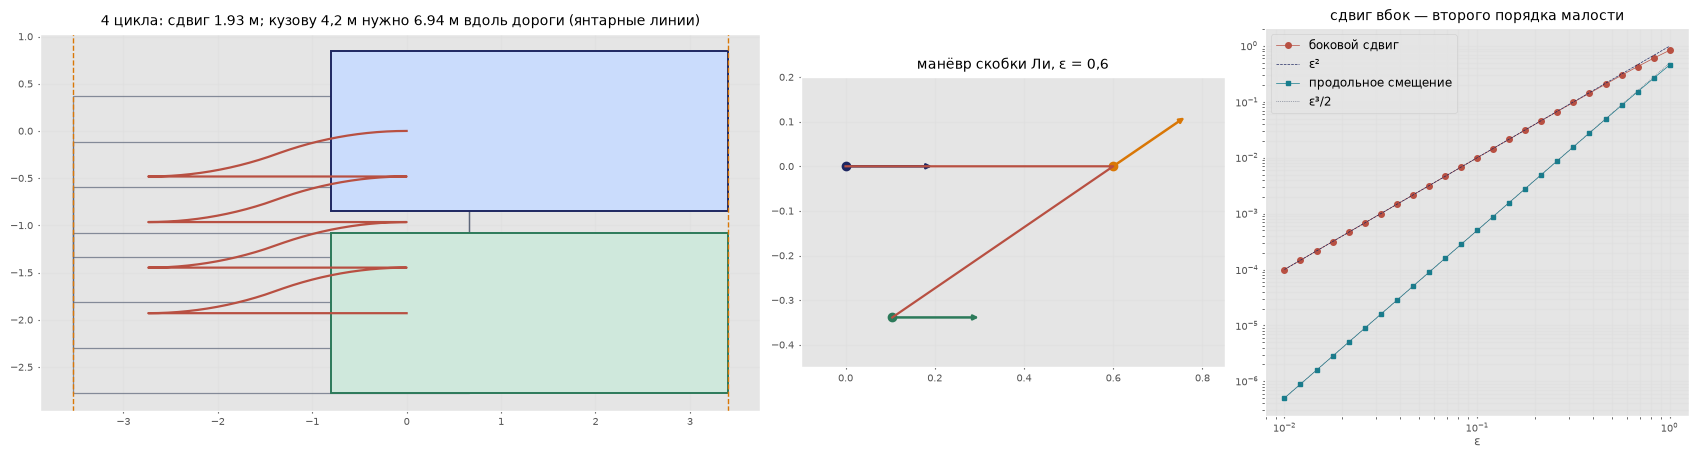

In [12]:
Rm = 4.0
for psi_d, ncyc in ((20.0, 4), (10.0, 16)):
    psi = rad(psi_d); path, keys = parking_path(Rm, psi, ncyc); C = np.vstack([car_corners(q) for q in path])
    print('ψ = %2.0f°: сдвиг за цикл %.3f м (ρψ² = %.3f), откат %.3f м;  после %d циклов сдвиг %.3f м;  для 1,93 м нужно %.1f цикла;  пятно кузова вдоль дороги %.2f м'
          % (psi_d, 2*Rm*(1 - np.cos(psi)), Rm*psi**2, 2*Rm*np.sin(psi), ncyc, -keys[-1, 1], 1.93/(2*Rm*(1 - np.cos(psi))), C[:, 0].max() - C[:, 0].min()))
    if psi_d == 20.0: path20, keys20, C20 = path, keys, C
print('угол руля при ρ_min = 4 м и базе 2,7 м: %.1f°' % deg(np.arctan(2.7/4.0)))
q0 = np.array([0.3, -0.2, 0.7]); br = lie_bracket_num(g1, g2, q0)
print('скобка Ли численно при θ = 0,7:', br.round(5), ';  (sin θ, −cos θ, 0) =', np.array([np.sin(0.7), -np.cos(0.7), 0]).round(5), ';  det[g₁ g₂ [g₁,g₂]] = %.3f' % np.linalg.det(np.column_stack([g1(q0), g2(q0), br])))
Pl, marks = lie_maneuver(0.6); print('манёвр при ε = 0,6: итог (%.3f; %.3f), курс %.1e;  ε² = %.2f' % (marks[-1, 0], marks[-1, 1], marks[-1, 2], 0.36))

fig, axs = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw={'width_ratios': [1.7, 1, 1]})
ax = axs[0]                                   # кузов 4,2 м: свес 0,8 м назад от задней оси, 3,4 м вперёд (car_corners)
for kq in keys20[2:-1:3]:
    cc = car_corners(kq); ax.plot(np.r_[cc[:, 0], cc[0, 0]], np.r_[cc[:, 1], cc[0, 1]], color=GREY, lw=0.9, alpha=0.7)
for kq, fc, ec in ((keys20[0], ICE, NAVY), (keys20[-1], '#CFE8DC', GREEN)):
    cc = car_corners(kq); ax.fill(cc[:, 0], cc[:, 1], facecolor=fc, edgecolor=ec, lw=1.4, zorder=2)
draw_path(ax, path20)
for xx in (C20[:, 0].min(), C20[:, 0].max()): ax.axvline(xx, color=AMB, ls='--', lw=1)
ax.set_aspect('equal'); ax.grid(alpha=.3); ax.set_title('4 цикла: сдвиг %.2f м; кузову 4,2 м нужно %.2f м вдоль дороги (янтарные линии)' % (-keys20[-1, 1], C20[:, 0].max() - C20[:, 0].min()), fontsize=10)
ax = axs[1]; draw_path(ax, Pl)
for m, col in zip(marks[[0, 2, 4]], (NAVY, AMB, GREEN)):
    ax.annotate('', xy=(m[0] + 0.2*np.cos(m[2]), m[1] + 0.2*np.sin(m[2])), xytext=(m[0], m[1]), arrowprops=dict(arrowstyle='-|>', color=col, lw=1.8)); ax.plot(m[0], m[1], 'o', color=col)
ax.set_aspect('equal'); ax.grid(alpha=.3); ax.set_xlim(-0.1, 0.85); ax.set_ylim(-0.45, 0.2); ax.set_title('манёвр скобки Ли, ε = 0,6', fontsize=10)
ax = axs[2]; es = np.logspace(-2, 0, 25); ends = np.array([lie_maneuver(e)[1][-1] for e in es])
ax.loglog(es, -ends[:, 1], 'o-', color=RED, ms=4, label='боковой сдвиг'); ax.loglog(es, es**2, color=NAVY, ls='--', label='ε²'); ax.loglog(es, ends[:, 0], 's-', color=TEAL, ms=3, label='продольное смещение'); ax.loglog(es, es**3/2, color=GREY, ls=':', label='ε³/2')
ax.set_xlabel('ε'); ax.grid(alpha=.3, which='both'); ax.legend(fontsize=8.5); ax.set_title('сдвиг вбок — второго порядка малости', fontsize=10)
plt.tight_layout(); plt.show()

## 11. Отслеживание траектории вынесенной точкой (§ 6.10)

Плоские выходы уницикла: $v=\sqrt{\dot x^2+\dot y^2}$, $\theta=\operatorname{atan2}(\dot y,\dot x)$, $\omega=\dfrac{\dot x\ddot y-\dot y\ddot x}{\dot x^2+\dot y^2}=v\kappa$, руль автомобиля $\delta=\operatorname{arctg}(d\kappa)$. Ожидаем для $\dot x=1$, $\dot y=0$, $\ddot y=0{,}2$: $\omega=0{,}2$ рад/с, $\rho=5$ м, $\delta=28{,}4^\circ$.
Вынесенная точка $B$ на расстоянии $l_B$ впереди $P$: $\dot{\mathbf p}_B=J_B(\theta)(v,\omega)^{\mathrm T}$, $\det J_B=l_B$; закон $(v,\omega)=J_B^{-1}\big(\dot{\mathbf p}_B^\ast+K(\mathbf p_B^\ast-\mathbf p_B)\big)$. Пример конспекта: $l_B=0{,}2$ м, $\theta=0$, $\dot{\mathbf p}_B=(0{,}3;\ 0{,}1)$ → $v=0{,}3$ м/с, $\omega=0{,}5$ рад/с.
Уницикл ведёт точку $B$ по восьмёрке $(\sin\Omega t,\ \tfrac12\sin2\Omega t)$ м, $\Omega=2\pi/20$ с⁻¹, $K=1$ с⁻¹, старт из начала координат курсом вдоль $X$. Сравниваем $l_B=0{,}1$, $0{,}2$, $0{,}5$ м: ошибка точки $B$ гаснет при любом $l_B$, но чем меньше $l_B$, тем ближе к кривой идёт сама ось колёс и тем больше нужны угловые скорости. Рядом — преследование точки упреждения: $\kappa=2\sin\eta/L_d$, где $\eta$ — угол между курсом и направлением на точку упреждения (при $L_d=1$ м и $\eta=30^\circ$ ожидаем $\kappa=1$ 1/м и $\omega=0{,}5$ рад/с при $v=0{,}5$ м/с).

плоские выходы: v = 1.0 м/с, θ = 0.0, ω = 0.20 рад/с, κ = 0.20 1/м, ρ = 5 м;  руль при d = 2,7 м: δ = 28.4° (допустимо: κ < 1/ρ_min = 0,25)
вынесенная точка: (v, ω) = J_B⁻¹(0,3; 0,1) при l_B = 0,2, θ = 0: [0.3 0.5]
pure pursuit: κ = 2 sin 30° / 1 = 1.00 1/м, ω = vκ = 0.50 рад/с при v = 0,5 м/с

 l_B, м | ошибка B в конце, мм | max отклонения P от кривой (2-й круг), м | max|ω| на 2-м круге | max|ω| в начале, рад/с


  0.1   |               0.36 |                                  0.021 |               0.94 | 3.14


  0.2   |               0.55 |                                  0.075 |               0.86 | 1.57


  0.5   |               1.04 |                                  0.375 |               0.75 | 0.65

pure pursuit по той же восьмёрке, v = 0,3 м/с:


  L_d = 0.3 м: max отклонения от кривой на втором круге 0.038 м, max|ω| = 1.00 рад/с


  L_d = 0.6 м: max отклонения от кривой на втором круге 0.190 м, max|ω| = 0.81 рад/с


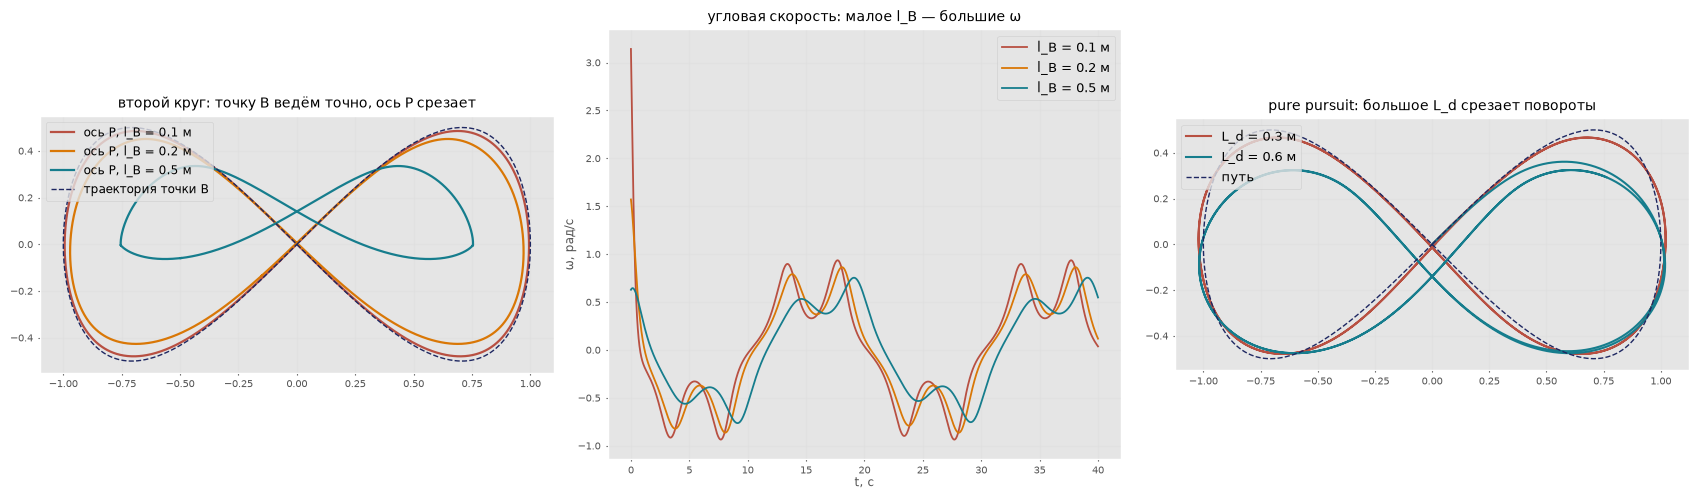

In [13]:
v_, th_, w_, k_ = flat_outputs(1.0, 0.0, 0.0, 0.2)
print('плоские выходы: v = %.1f м/с, θ = %.1f, ω = %.2f рад/с, κ = %.2f 1/м, ρ = %.0f м;  руль при d = 2,7 м: δ = %.1f° (допустимо: κ < 1/ρ_min = 0,25)' % (v_, th_, w_, k_, 1/k_, deg(np.arctan(2.7*k_))))
print('вынесенная точка: (v, ω) = J_B⁻¹(0,3; 0,1) при l_B = 0,2, θ = 0:', np.round(lookahead_control(np.zeros(3), [0.2, 0.0], [0.3, 0.1], 0.2, 0.0), 4))
print('pure pursuit: κ = 2 sin 30° / 1 = %.2f 1/м, ω = vκ = %.2f рад/с при v = 0,5 м/с' % (pure_pursuit_kappa(rad(30), 1.0), 0.5*pure_pursuit_kappa(rad(30), 1.0)))
curve = np.array([figure_eight(t)[0] for t in np.linspace(0, 20, 4001)])
fig, axs = plt.subplots(1, 3, figsize=(17, 5))
print('\n l_B, м | ошибка B в конце, мм | max отклонения P от кривой (2-й круг), м | max|ω| на 2-м круге | max|ω| в начале, рад/с')
for lB, col in ((0.1, RED), (0.2, AMB), (0.5, TEAL)):
    t, Q, PB, U = track_lookahead(figure_eight, (0.0, 0.0, 0.0), lB, 1.0, 40.0, 0.01)
    ref = np.array([figure_eight(tt)[0] for tt in t]); eB = np.hypot(*(PB - ref).T)
    dP = np.array([np.min(np.hypot(curve[:, 0] - q[0], curve[:, 1] - q[1])) for q in Q[2000::5]])
    print('  %.1f   | %18.2f | %38.3f | %18.2f | %.2f' % (lB, 1e3*eB[-1], dP.max(), np.abs(U[2000:, 1]).max(), np.abs(U[:200, 1]).max()))
    axs[0].plot(Q[2000:, 0], Q[2000:, 1], color=col, lw=1.6, label='ось P, l_B = %.1f м' % lB); axs[1].plot(t, U[:, 1], color=col, lw=1.3, label='l_B = %.1f м' % lB)
axs[0].plot(curve[:, 0], curve[:, 1], color=NAVY, lw=1, ls='--', label='траектория точки B'); axs[0].set_aspect('equal'); axs[0].grid(alpha=.3); axs[0].legend(fontsize=8.5, loc='upper left')
axs[0].set_title('второй круг: точку B ведём точно, ось P срезает', fontsize=10)
axs[1].set_xlabel('t, с'); axs[1].set_ylabel('ω, рад/с'); axs[1].grid(alpha=.3); axs[1].legend(fontsize=9); axs[1].set_title('угловая скорость: малое l_B — большие ω', fontsize=10)
print('\npure pursuit по той же восьмёрке, v = 0,3 м/с:')
curve2 = np.array([figure_eight(t)[0] for t in np.linspace(0, 60, 12001)])     # путь на три круга вперёд
for Ld, col in ((0.3, RED), (0.6, TEAL)):
    Qp, Wp = track_pure_pursuit(curve2, (0.0, 0.0, np.pi/4), 0.3, Ld, 40.0, 0.01)
    dP = np.array([np.min(np.hypot(curve[:, 0] - q[0], curve[:, 1] - q[1])) for q in Qp[2000::5]])
    print('  L_d = %.1f м: max отклонения от кривой на втором круге %.3f м, max|ω| = %.2f рад/с' % (Ld, dP.max(), np.abs(Wp[2000:]).max()))
    axs[2].plot(Qp[:, 0], Qp[:, 1], color=col, lw=1.5, label='L_d = %.1f м' % Ld)
axs[2].plot(curve[:, 0], curve[:, 1], color=NAVY, lw=1, ls='--', label='путь'); axs[2].set_aspect('equal'); axs[2].grid(alpha=.3); axs[2].legend(fontsize=9, loc='upper left')
axs[2].set_title('pure pursuit: большое L_d срезает повороты', fontsize=10)
plt.tight_layout(); plt.show()

## 12. Мобильный манипулятор (пример 6.8) (§ 6.11, пример 6.8)

Плоская часть: $\dot{\mathbf p}_e=R(\theta)\,J\begin{pmatrix}\dot{\boldsymbol\xi}_R\\ \dot{\mathbf q}\end{pmatrix}$, $J=\begin{pmatrix}J_{\mathrm{base}}&J_{\mathrm{arm}}\end{pmatrix}$, $J_{\mathrm{base}}=\begin{pmatrix}1&0&-r_{Pe,y}\\ 0&1&r_{Pe,x}\end{pmatrix}$; взвешенная псевдообратная $J_D^{+}=D^{-1}J^{\mathrm T}(JD^{-1}J^{\mathrm T})^{-1}$.
Пример 6.8: двухзвенник $a_1=a_2=0{,}3$ м в точке $P$ меканум-платформы, $q_1=0$, $q_2=90^\circ$, $\theta=0$, требуемая скорость схвата $(0{,}1;\ 0)$ м/с. Ожидаем: равные веса — $v_x\approx0{,}080$, $v_y\approx0{,}012$ м/с, $\omega\approx-0{,}020$, $\dot q_1\approx-0{,}020$, $\dot q_2\approx-0{,}024$ рад/с; веса платформы ×100 — $v_x\approx0{,}009$ м/с, $\dot q_2\approx-0{,}275$ рад/с; веса руки ×100 — $v_x\approx0{,}092$ м/с. Скорости колёс — $\dot{\boldsymbol\varphi}=H\dot{\boldsymbol\xi}_R$.
Затем то же в пространстве: UR5e (`kinlib.make_ur5e`, официальная таблица ДХ) на той же меканум-платформе, $J_e=\begin{pmatrix}J_{\mathrm{base},6}F & J_{\mathrm{arm}}\end{pmatrix}$ размера $6\times10$ в порядке kinlib $[\mathbf v;\boldsymbol\omega]$, $F=H^{+}$. Сверяем блок руки с `roboticstoolbox` (модель DHRobot по той же таблице) и весь $J_e$ — с конечными разностями. Веса здесь работают и как согласование единиц: поворот колеса на радиан сдвигает платформу лишь на сантиметр с небольшим, поэтому при равных весах почти всё движение берёт рука, а платформу «включают» тяжёлыми весами на сочленениях.

r_Pe = (0.3; 0.3) м;  J =
 [[ 1.   0.  -0.3 -0.3 -0.3]
 [ 0.   1.   0.3  0.3  0. ]]
равные веса    : (v_x, v_y, ω) = (0.0805; 0.0123; -0.0205), (q̇₁, q̇₂) = (-0.0205; -0.0241);  J·z = [ 0.1 -0. ];  колёса φ̇ = [1.522 1.698 2.013 1.207] рад/с
платформа ×100 : (v_x, v_y, ω) = (0.0092; 0.0083; -0.0003), (q̇₁, q̇₂) = (-0.0273; -0.2752);  J·z = [0.1 0. ];  колёса φ̇ = [0.02  0.347 0.351 0.016] рад/с
рука ×100      : (v_x, v_y, ω) = (0.0922; 0.0077; -0.0254), (q̇₁, q̇₂) = (-0.0003; -0.0003);  J·z = [0.1 0. ];  колёса φ̇ = [1.886 1.803 2.194 1.496] рад/с

UR5e в точке P платформы, q = [   0.  -60.   90. -120.  -90.    0.] °: схват в осях платформы [-0.6519 -0.1333  0.2349] м;  J_e размера (6, 10)
блок руки: max|J_arm(kinlib) − jacob0(rtb)| = 1.1e-16
весь J_e против центральных разностей: max|Δ| = 1.3e-10
равные веса : колёса φ̇ = [0.016 0.025 0.025 0.016] рад/с (платформа ξ̇_R = [0.001  0.0002 0.    ]), рука q̇ = [ 0.    -0.202  0.328 -0.126 -0.     0.   ] рад/с;  остаток |J_e z − заданное| =

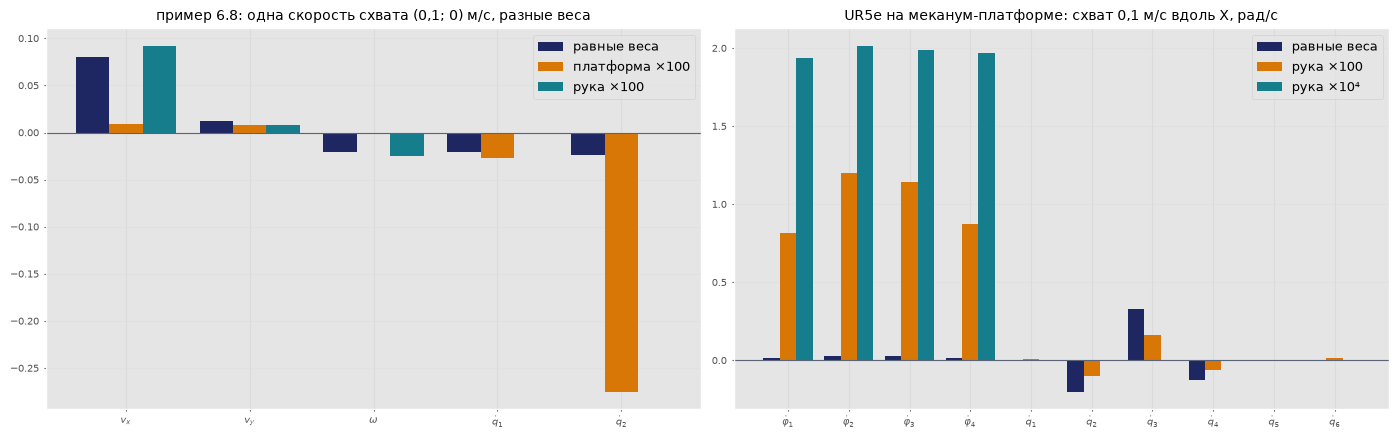

In [14]:
q = np.array([0.0, np.pi/2]); r_pe = planar2r_fk(q); J = mobile_manip_J(r_pe, planar2r_J(q)) + 0.0
print('r_Pe = (%.1f; %.1f) м;  J =\n' % tuple(r_pe), J.round(3))
labels = ['v_x', 'v_y', 'ω', 'q̇₁', 'q̇₂']; Z = {}
for nm, D in (('равные веса', np.ones(5)), ('платформа ×100', np.array([100., 100., 100., 1., 1.])), ('рука ×100', np.array([1., 1., 1., 100., 100.]))):
    z = weighted_pinv(J, D).dot([0.1, 0.0]); Z[nm] = z
    print('%-15s: (v_x, v_y, ω) = (%.4f; %.4f; %.4f), (q̇₁, q̇₂) = (%.4f; %.4f);  J·z = %s;  колёса φ̇ = %s рад/с'
          % ((nm,) + tuple(z) + (str((J.dot(z) + 0.0).round(6)), str(mec_H().dot(z[:3]).round(3)))))
fig, axs = plt.subplots(1, 2, figsize=(14, 4.4))
ax = axs[0]; wdt = 0.27
for i, (nm, z) in enumerate(Z.items()): ax.bar(np.arange(5) + (i - 1)*wdt, z, wdt, color=(NAVY, AMB, TEAL)[i], label=nm)
ax.axhline(0, color=GREY, lw=.8); ax.set_xticks(range(5)); ax.set_xticklabels(['$v_x$', '$v_y$', r'$\omega$', r'$\dot q_1$', r'$\dot q_2$']); ax.grid(alpha=.3, axis='y'); ax.legend(fontsize=9)
ax.set_title('пример 6.8: одна скорость схвата (0,1; 0) м/с, разные веса', fontsize=10)

# UR5e на меканум-платформе
import kinlib
ur = kinlib.make_ur5e(); qa = rad([0.0, -60.0, 90.0, -120.0, -90.0, 0.0]); ur.forward(qa)
Ja = ur.jacobian.copy(); pe = ur.end_frame.t_3_1.reshape(3)
Fm = mec_Hpinv(); Je = np.hstack([base_twist_J6(pe).dot(Fm), Ja])
print('\nUR5e в точке P платформы, q =', deg(qa).round(0), '°: схват в осях платформы', pe.round(4), 'м;  J_e размера', Je.shape)
if rtb is not None:
    rob = rtb.DHRobot([rtb.RevoluteDH(d=r_[0], a=r_[1], alpha=r_[2], offset=r_[3]) for r_ in kinlib.UR5E_DH])
    print('блок руки: max|J_arm(kinlib) − jacob0(rtb)| = %.1e' % np.abs(Ja - rob.jacob0(qa)).max())
def ee_world(dphi_wheels, qarm):
    """Поза схвата в мировых осях после поворота колёс на dphi_wheels (рад) из ξ = 0: ξ' = exp на SE(2) от F·Δφ."""
    xi = se2_exp(np.zeros(3), *(Fm.dot(dphi_wheels)), 1.0)
    Tb = np.eye(4); Tb[:2, :2] = [[np.cos(xi[2]), -np.sin(xi[2])], [np.sin(xi[2]), np.cos(xi[2])]]; Tb[:2, 3] = xi[:2]
    ur.forward(qarm); return Tb.dot(ur.end_frame.t_4_4)
T0 = ee_world(np.zeros(4), qa); Jn = np.zeros((6, 10)); h = 1e-6
for j in range(10):
    e_ = np.zeros(10); e_[j] = h
    Tp, Tm = ee_world(e_[:4], qa + e_[4:]), ee_world(-e_[:4], qa - e_[4:])      # центральные разности
    Jn[:3, j] = (Tp[:3, 3] - Tm[:3, 3])/(2*h); Jn[3:, j] = kinlib.vee((Tp[:3, :3] - Tm[:3, :3]).dot(T0[:3, :3].T))/(2*h)
print('весь J_e против центральных разностей: max|Δ| = %.1e' % np.abs(Je - Jn).max())
tw = np.array([0.1, 0.0, 0.0, 0.0, 0.0, 0.0])
W3 = (('равные веса', np.ones(10)), ('рука ×100', np.r_[np.ones(4), 100*np.ones(6)]), ('рука ×10⁴', np.r_[np.ones(4), 1e4*np.ones(6)]))
for nm, D in W3:
    z = weighted_pinv(Je, D).dot(tw)
    print('%-12s: колёса φ̇ = %s рад/с (платформа ξ̇_R = %s), рука q̇ = %s рад/с;  остаток |J_e z − заданное| = %.1e'
          % (nm, z[:4].round(3), Fm.dot(z[:4]).round(4), z[4:].round(3), np.abs(Je.dot(z) - tw).max()))
print('единицы: поворот одного колеса на 1 рад сдвигает платформу вперёд всего на r/4 = %.4f м, а поворот сочленения UR5e на 1 рад сдвигает схват на десятки сантиметров;\n'
      'поэтому при равных весах решение минимальной нормы почти всё отдаёт руке, и платформу «включают» весами' % (MEC_R/4))
ax = axs[1]
for i, (nm, D) in enumerate(W3):
    ax.bar(np.arange(10) + (i - 1)*wdt, weighted_pinv(Je, D).dot(tw), wdt, color=(NAVY, AMB, TEAL)[i], label=nm)
ax.axhline(0, color=GREY, lw=.8); ax.set_xticks(range(10)); ax.set_xticklabels([r'$\dot\varphi_%d$' % k for k in range(1, 5)] + [r'$\dot q_%d$' % k for k in range(1, 7)]); ax.grid(alpha=.3, axis='y'); ax.legend(fontsize=9)
ax.set_title('UR5e на меканум-платформе: схват 0,1 м/с вдоль X, рад/с', fontsize=10)
plt.tight_layout(); plt.show()

## 13. Интерактивная модель меканум-платформы (§ 6.8)

Ползунки $(v_x,v_y,\omega)$: скорости четырёх колёс $\dot{\boldsymbol\varphi}=H\dot{\boldsymbol\xi}_R$, выход за ограничение $\dot\varphi_{\max}=20$ рад/с (вне октаэдра команду нужно масштабировать целиком), положение МЦВ $(-v_y/\omega,\ v_x/\omega)$ в связанных осях и траектория за 4 с. При $v_y=0$ платформа ведёт себя как дифференциальная схема: МЦВ лежит на поперечной оси. Статичный кадр — команда примера 6.6.

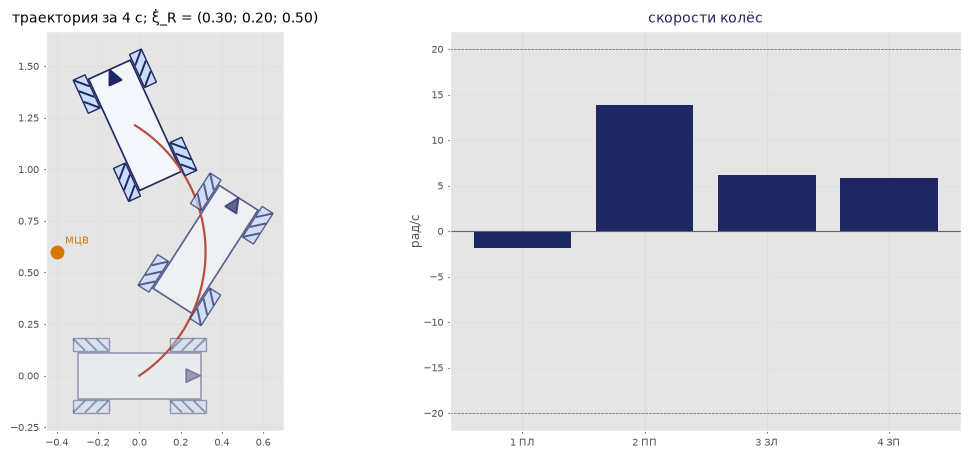

φ̇ = [-1.85 13.85  6.15  5.85] рад/с;  |v_x| + |v_y| + (l_x + l_y)|ω| = 0.693 м/с при пределе r φ̇_max = 1.00 м/с


interactive(children=(FloatSlider(value=0.3, description='vx', max=1.0, min=-1.0, step=0.05), FloatSlider(valu…

In [15]:
def show_mecanum(vx=0.3, vy=0.2, omega=0.5):
    u = np.array([vx, vy, omega]); ph = mec_H().dot(u); over = np.abs(ph).max() > 20.0
    fig, axs = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={'width_ratios': [1.5, 1]})
    ax = axs[0]; Pm = simulate_body(lambda t: u, T=4.0, n=200); draw_path(ax, Pm)
    for k in (0, 100, 200): draw_mecanum(ax, Pm[k], alpha=0.4 + 0.6*k/200)
    if abs(omega) > 1e-6:
        icc = np.array([-vy/omega, vx/omega]); ax.plot(icc[0], icc[1], 'o', color=AMB, ms=9); ax.annotate('МЦВ', icc, textcoords='offset points', xytext=(6, 6), color=AMB)
    ax.set_aspect('equal'); ax.grid(alpha=.3); ax.set_title('траектория за 4 с; ξ̇_R = (%.2f; %.2f; %.2f)' % (vx, vy, omega), fontsize=10)
    ax = axs[1]; ax.bar(range(1, 5), ph, color=[RED if abs(p) > 20 else NAVY for p in ph]); ax.axhline(20, color=GREY, ls='--'); ax.axhline(-20, color=GREY, ls='--'); ax.axhline(0, color=GREY, lw=.8)
    ax.set_xticks(range(1, 5)); ax.set_xticklabels(['1 ПЛ', '2 ПП', '3 ЗЛ', '4 ЗП']); ax.set_ylabel('рад/с'); ax.grid(alpha=.3, axis='y')
    ax.set_title('скорости колёс' + (': ВНЕ октаэдра, команду нужно масштабировать' if over else ''), color=RED if over else NAVY, fontsize=10)
    plt.tight_layout(); plt.show()
    print('φ̇ =', ph.round(2), 'рад/с;  |v_x| + |v_y| + (l_x + l_y)|ω| = %.3f м/с при пределе r φ̇_max = %.2f м/с' % (abs(vx) + abs(vy) + (MEC_LX + MEC_LY)*abs(omega), MEC_R*20))

show_mecanum(0.3, 0.2, 0.5)     # статичный кадр: пример 6.6
if interact is not None:
    interact(show_mecanum, vx=FloatSlider(min=-1, max=1, step=0.05, value=0.3), vy=FloatSlider(min=-1, max=1, step=0.05, value=0.2), omega=FloatSlider(min=-2.6, max=2.6, step=0.1, value=0.5))